<a href="https://colab.research.google.com/github/tovarrog24/Emergency-Department-Volume-and-Capacity/blob/main/code/trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Emergency Department Forecasting and Optimization

**Class:** CS-4330-D10, Introduction to Data Science, Fall 2026 (Angelo State University, Dr. Dogdu)

**Team (Group 2):**

- Rogelio "Anthony" Tovar, rtovar3@angelo.edu, major: Mathematics
- Virgil Rogers, vrogers4@angelo.edu, major: Artificial Intelligence

**Project description:** Emergency departments (EDs) are where demand for hospital care is least predictable. When an ED sees more patients than its treatment stations can handle, wait times grow and care suffers. Our project uses California's hospital-level ED data to find which hospitals carry the heaviest ED load, how that load relates to hospital size and type, and which kinds of hospitals look alike, so that planners can see where added capacity is most needed.

**Dataset summary:**

- Source: *Emergency Department Volume and Capacity, 2021–2023*, California Department of Health Care Access and Information (HCAI), via Data.gov: https://catalog.data.gov/dataset/emergency-department-volume-and-capacity
- Original size: 12,849 rows and 18 features (one row per hospital, year, and diagnosis category).
- File used here: `ED_Cleaned.csv`, the hospital-level table from Progress Report #1, with 756 rows (one per hospital per year, 297 hospitals) and 19 features.
- Schema: identifiers (`oshpd_id`, `FacilityName2`, `CountyName`, `system`); numerical features (`year`, `Tot_ED_NmbVsts`, `EDStations`, `ED_Burden`, `Bed_Size_Rank`, `LATITUDE`, `LONGITUDE`, `LAT_STD`, `LON_STD`); categorical features (`LICENSED_BED_SIZE`, `HospitalOwnership`, `UrbanRuralDesi`, `TEACHINGDesignation`, `PrimaryCareShortageArea`, `MentalHealthShortageArea`). `ED_Burden` is total ED visits divided by ED treatment stations.

**Project goals:**

1. Predict how heavily a hospital's ED is used from its size and type (regression).
2. Classify hospitals by setting and type (classification).
3. Group hospitals with similar demand profiles (clustering, Report #4).

**Report title:** Progress Report #5: Decision Trees and Ensemble Learning

Sections 1 and 3.1: Rogelio Tovar. Sections 2, 3.2, and 3.3, the write-up, and the conclusion: Virgil Rogers.

## 0. Setup

We import the libraries used throughout the notebook and load the cleaned dataset. When the repository is cloned, the notebook reads `../dataset/ED_Cleaned.csv`. When it is opened in Colab straight from GitHub, that folder is not available, so it loads the same file from our repository.

In [1]:
# Progress Report #5: Decision Trees and Ensemble Learning | Group 2 (Tovar and Rogers) | CS-4330-D10, Fall 2026

# Import packages
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn import tree, metrics
from sklearn.metrics import r2_score
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

from pathlib import Path
import warnings
warnings.simplefilter("ignore")
LOCAL_PATH = Path("../dataset/ED_Cleaned.csv")
REPO_URL = ("https://raw.githubusercontent.com/tovarrog24/"
"Emergency-Department-Volume-and-Capacity/main/dataset/ED_Cleaned.csv")
source = LOCAL_PATH if LOCAL_PATH.exists() else REPO_URL
data = pd.read_csv(source)
print("Loaded from:", source)
print("Shape:", data.shape)

Loaded from: ../dataset/ED_Cleaned.csv
Shape: (756, 19)


The file loads with 756 rows and 19 columns, one row per California hospital per year.

## 1. Decision Tree Regression

Task: build and train a Decision Tree Regressor, evaluate it with regression metrics (R², RMSE, MAE), visualize the tree or its feature importances, and tune hyperparameters such as `max_depth` and `min_samples_split` to observe and prevent overfitting.

A regression tree predicts a number by asking a series of yes/no questions about the inputs (for example, "does this ED have 27.5 stations or fewer?") and returning the average of the training hospitals that end up in the same final group, called a leaf. A deeper tree asks more questions and fits the training data more closely, but it can start memorizing noise. That is the overfitting the tuning steps are meant to catch.

### 1.1 Total ED visits from ED stations: a first tree

In Report #2, a straight regression line of visits on stations reached R² = 0.687. Here we fit a small tree, only two levels deep, to the same pair of variables so we can compare.

|--- EDStations <= 27.50
|   |--- EDStations <= 13.50
|   |   |--- value: [13833.10]
|   |--- EDStations >  13.50
|   |   |--- value: [30830.63]
|--- EDStations >  27.50
|   |--- EDStations <= 52.50
|   |   |--- value: [54090.47]
|   |--- EDStations >  52.50
|   |   |--- value: [82690.43]



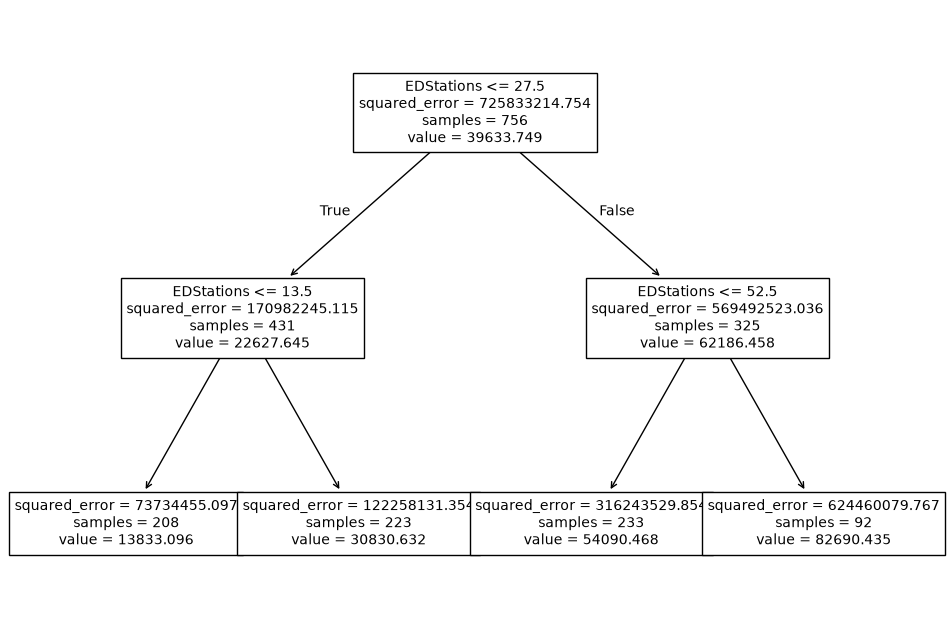

In [2]:
#Our best regression fit was the regression line when we compared ED stations to total ED visits
#The number to beat is R^2 = 0.687

X = data[["EDStations"]]
y = data[["Tot_ED_NmbVsts"]]

regtreeModel = DecisionTreeRegressor(max_depth=2, min_samples_leaf=2, random_state=42)
regtreeModel.fit(X, y);

print(export_text(regtreeModel, feature_names=X.columns.to_list()))

# Using tree.plot_tree() makes a cleaner figure

# Resize the plotting window
plt.figure(figsize=[12, 8])

p = tree.plot_tree(
    regtreeModel,
    feature_names=X.columns,
    filled=False,
    fontsize=10)

# Add the predictions to the original data set
data["pred"] = regtreeModel.predict(X)

The tree asks two questions about station count and sorts every hospital into one of four groups. EDs with 13 or fewer stations are predicted to see about 13,800 visits a year; 14 to 27 stations, about 30,800; 28 to 52 stations, about 54,100; and more than 52 stations, about 82,700. Each box in the diagram shows the split, the squared error of the group, how many hospital-years reach it, and the average number of visits, which is the value the tree predicts.

Next we plot each hospital's predicted visits against its station count and score the tree on the same data it was trained on.

229808729.8234679
R^2: 0.6833863136157791


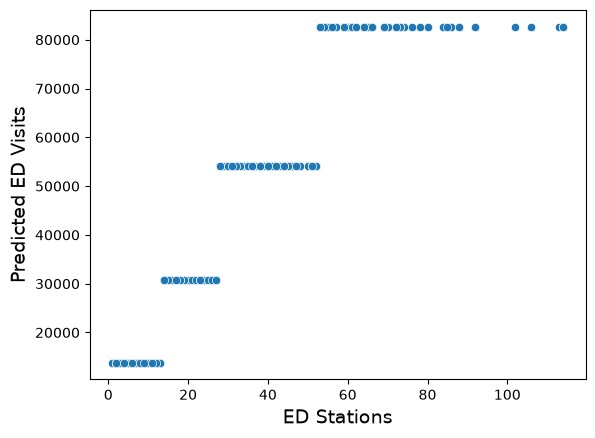

In [3]:
# Plot observed vs. predictions
p = sns.scatterplot(data=data, x="EDStations", y="pred")
p.set_xlabel("ED Stations", fontsize=14)
p.set_ylabel("Predicted ED Visits", fontsize=14)

# Calculate MSE
print(metrics.mean_squared_error(data["pred"], y))

#Calculate the Coefficient of Determination
r_squared = regtreeModel.score(X, y)
print("R^2:", r_squared)

Because the tree can only return four values, its predictions form four flat steps. Even so, it explains 68.3% of the variation in visits (R² = 0.683, MSE about 229.8 million). That is almost exactly what the straight line in Report #2 achieved (0.687), so four simple groups capture nearly as much as a full linear fit. Like the line, the tree misses most at the large EDs, where hospitals with similar station counts can differ by tens of thousands of visits.

### 1.2 Tuning the depth and number of leaves

To choose how large the tree should be, we try every combination of maximum depth (1 to 20) and maximum number of leaves (2 to 40), keeping at least 2 hospitals in each leaf. Each combination is scored with 5-fold cross-validation, so the error is always measured on data the tree did not train on. The combination with the lowest cross-validated mean squared error (MSE) wins. The surface plot shows the error for every combination, with the minimum marked in red.

Optimal Leaves: 29
Optimal Depth: 5
Minimum CV MSE: 190325816.6996816


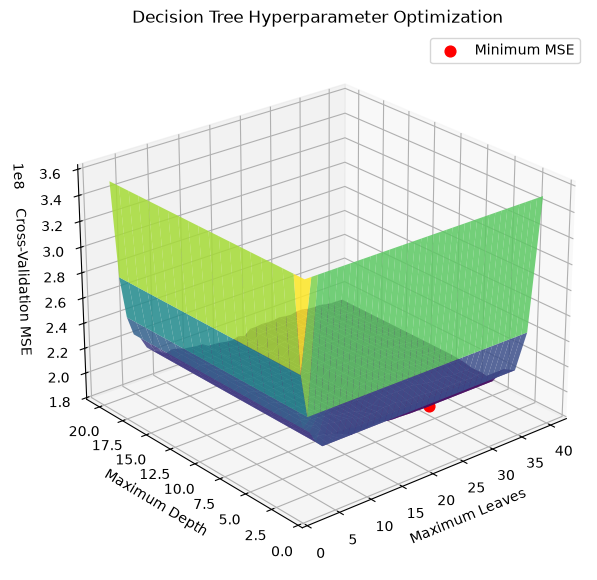

In [4]:
#Figuring out the best number of leaves and depth. We build a table where each (max leaves, max depth) pair gets its
#cross-validated MSE, plot it as a surface in 3 space, and take the point with the lowest error. Because we use
#cross-validation, the error is measured on data the tree did not see, which guards against overfitting.


from sklearn.model_selection import KFold, cross_val_score

# Hyperparameter ranges
depthValues = range(1, 21)
leafValues = range(2, 41)

# Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store results
results = []

for depth in depthValues:
    for leaves in leafValues:

        model = DecisionTreeRegressor(
            max_depth=depth,
            max_leaf_nodes=leaves,
            min_samples_leaf=2,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        results.append({
            "Max_Leaves": leaves,
            "Max_Depth": depth,
            "MSE": -scores.mean()
        })

# Create results dataset
treeResults = pd.DataFrame(results)

# Find minimum error
bestRow = treeResults.loc[treeResults["MSE"].idxmin()]

print("Optimal Leaves:", int(bestRow["Max_Leaves"]))
print("Optimal Depth:", int(bestRow["Max_Depth"]))
print("Minimum CV MSE:", bestRow["MSE"])

# Convert results into a surface
surface = treeResults.pivot(
    index="Max_Depth",
    columns="Max_Leaves",
    values="MSE"
)

# 3D surface of the cross-validated error
from mpl_toolkits.mplot3d import Axes3D

leafGrid, depthGrid = np.meshgrid(surface.columns.to_numpy(), surface.index.to_numpy())
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(leafGrid, depthGrid, surface.to_numpy(), cmap="viridis", alpha=0.85)
ax.scatter([bestRow["Max_Leaves"]], [bestRow["Max_Depth"]], [bestRow["MSE"]], color="red", s=60, label="Minimum MSE")
ax.set_xlabel("Maximum Leaves")
ax.set_ylabel("Maximum Depth")
ax.set_zlabel("Cross-Validation MSE")
ax.set_title("Decision Tree Hyperparameter Optimization")
ax.view_init(elev=25, azim=-130)
ax.legend()
plt.show()

The lowest cross-validated MSE, about 190.3 million (an RMSE of roughly 13,800 visits), comes from a tree with a maximum depth of 5 and at most 29 leaves. The surface shows the trade-off. Very shallow trees with few leaves sit high on the surface because they are too simple to follow the data (underfitting). Past the minimum, the surface flattens rather than dropping further: once the tree has about 29 leaves and 5 levels, extra depth or leaves stop improving predictions on hospitals the tree has not seen. Choosing the smallest tree near the bottom of that surface is how the search guards against overfitting.

### 1.3 Tuning the minimum samples needed to split

With depth and leaves fixed at their best values, we search for the best `min_samples_split`, the smallest number of hospitals a node must contain before the tree is allowed to split it. The search starts at 20 with a step of 15, moves to whichever neighbor lowers the cross-validated error, and halves the step each time no neighbor improves, stopping when the step reaches 1. The plot shows every value the search evaluated.

New starting point: 5 | Step size: 15 | MSE: 192821382.0537447
New starting point: 2 | Step size: 3 | MSE: 190325816.6996816

Optimal min_samples_split: 2
Minimum CV MSE found: 190325816.6996816


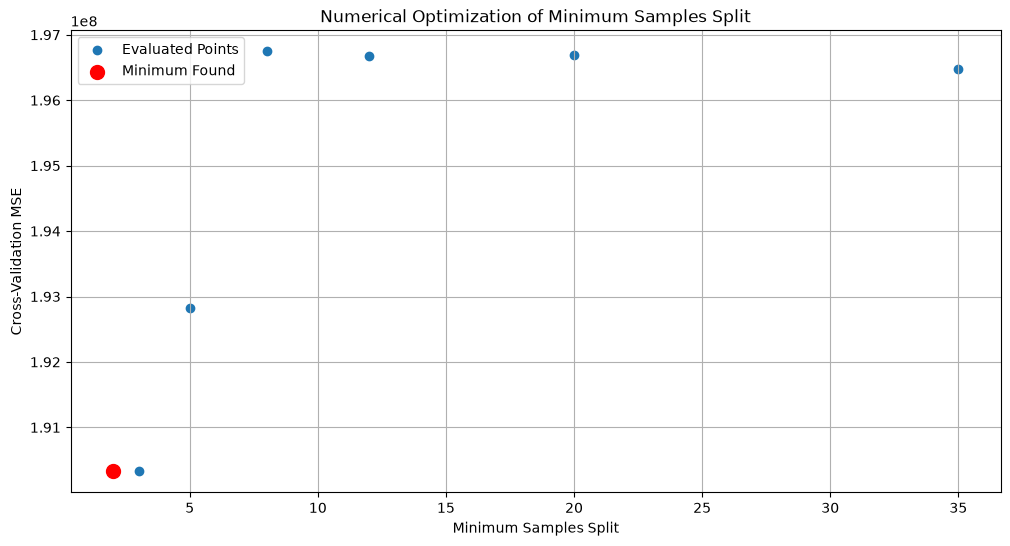

In [5]:
#To find the best min_samples_split, we use numerical methods similar to newtons method and bijections.

# Keep previously optimized hyperparameters
bestDepth = int(bestRow["Max_Depth"])
bestLeaves = int(bestRow["Max_Leaves"])

# Use the same cross-validation procedure
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store evaluated values to avoid redundant calculations
splitErrors = {}

# Define the error function
def calculateError(s):

    if s not in splitErrors:

        model = DecisionTreeRegressor(
            max_depth=bestDepth,
            max_leaf_nodes=bestLeaves,
            min_samples_leaf=2,
            min_samples_split=s,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        splitErrors[s] = -scores.mean()

    return splitErrors[s]

# Initial starting point and step size
s = 20
h = 15

# Numerical optimization
while h >= 1:

    while True:

        # Evaluate the current point and its neighbors
        candidates = [s]

        if s - h >= 2:
            candidates.append(s - h)

        if s + h <= len(X):
            candidates.append(s + h)

        # Find the candidate with the lowest error
        newS = min(candidates, key=calculateError)

        # Move only if the error strictly decreases
        if calculateError(newS) < calculateError(s):
            s = newS

            print("New starting point:", s,
                  "| Step size:", h,
                  "| MSE:", calculateError(s))

        else:
            break

    # Reduce the step size
    h = h // 2

# Final results
bestSplit = s

print("\nOptimal min_samples_split:", bestSplit)
print("Minimum CV MSE found:", calculateError(bestSplit))

# Create a dataset of evaluated points
splitResults = pd.DataFrame({
    "Min_Samples_Split": list(splitErrors.keys()),
    "MSE": list(splitErrors.values())
})

splitResults = splitResults.sort_values("Min_Samples_Split")

# Plot the evaluated points
plt.figure(figsize=(12, 6))

plt.scatter(
    splitResults["Min_Samples_Split"],
    splitResults["MSE"],
    label="Evaluated Points"
)

plt.scatter(
    bestSplit,
    calculateError(bestSplit),
    color="red",
    s=100,
    label="Minimum Found"
)

plt.xlabel("Minimum Samples Split")
plt.ylabel("Cross-Validation MSE")
plt.title("Numerical Optimization of Minimum Samples Split")
plt.legend()
plt.grid()
plt.show()

The search moved from 20 down to 5 and then to 2, where the cross-validated MSE reached its lowest value, 190.3 million, the same minimum found in the grid search. A `min_samples_split` of 2 is the default, so this setting adds no extra restriction. That makes sense here: the tree already requires at least 2 hospital-years in every leaf and is capped at 29 leaves, so those limits are doing the work of preventing overfitting. Larger values of `min_samples_split` (8 to 35) raised the error to about 197 million, which shows that forcing larger nodes before splitting made the tree too coarse. As with any search that moves step by step, this one could in principle stop at a local minimum, but the plotted points rise steadily on both sides of the minimum, which suggests it found the best value in this range.

### 1.4 The tuned regression tree

We now fit the tree with all of the tuned settings. The text version prints every split and leaf. The diagram shows the top three levels so the labels stay readable; the deeper levels continue the same pattern of narrowing station ranges.

|--- EDStations <= 27.50
|   |--- EDStations <= 13.50
|   |   |--- EDStations <= 9.50
|   |   |   |--- EDStations <= 4.50
|   |   |   |   |--- EDStations <= 2.50
|   |   |   |   |   |--- value: [2071.50]
|   |   |   |   |--- EDStations >  2.50
|   |   |   |   |   |--- value: [4787.67]
|   |   |   |--- EDStations >  4.50
|   |   |   |   |--- EDStations <= 7.50
|   |   |   |   |   |--- value: [8852.24]
|   |   |   |   |--- EDStations >  7.50
|   |   |   |   |   |--- value: [11760.39]
|   |   |--- EDStations >  9.50
|   |   |   |--- EDStations <= 10.50
|   |   |   |   |--- value: [24756.80]
|   |   |   |--- EDStations >  10.50
|   |   |   |   |--- value: [18866.88]
|   |--- EDStations >  13.50
|   |   |--- EDStations <= 23.50
|   |   |   |--- EDStations <= 17.50
|   |   |   |   |--- EDStations <= 16.50
|   |   |   |   |   |--- value: [27502.73]
|   |   |   |   |--- EDStations >  16.50
|   |   |   |   |   |--- value: [16750.38]
|   |   |   |--- EDStations >  17.50
|   |   |   |   |--- EDSt

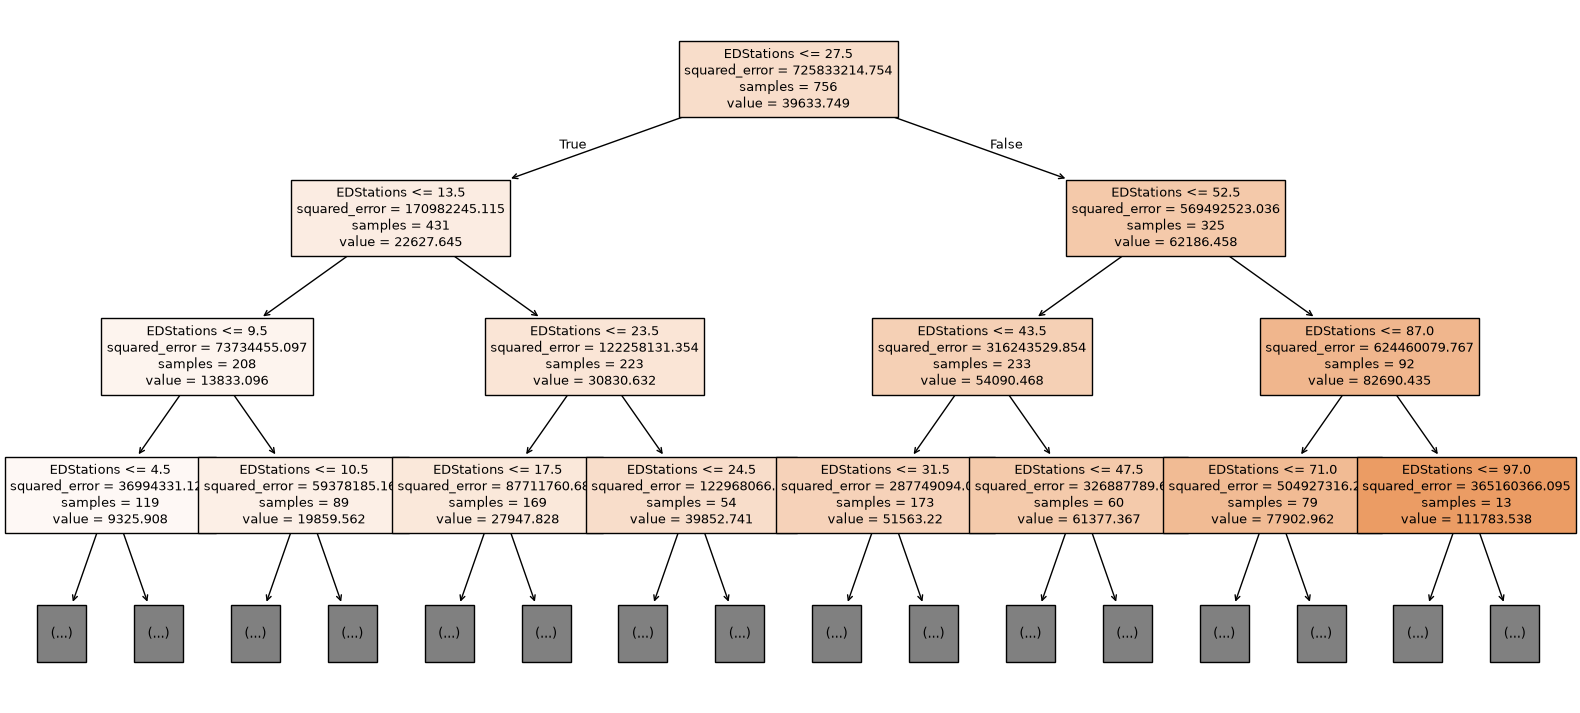

In [6]:
#New completley optimized regression tree

#Using the optimal, this is the new regression tree.

regtreeModelTotallyOptimal = DecisionTreeRegressor(max_depth=bestDepth, max_leaf_nodes=bestLeaves,
                                                   min_samples_leaf=2, min_samples_split=bestSplit, random_state=42)
regtreeModelTotallyOptimal.fit(X, y);

print(export_text(regtreeModelTotallyOptimal, feature_names=X.columns.to_list()))

# Add the predictions to the original data set
data["pred"] = regtreeModelTotallyOptimal.predict(X)

plt.figure(figsize=[20, 9])

p = tree.plot_tree(
    regtreeModelTotallyOptimal,
    feature_names=X.columns,
    max_depth=3,
    filled=True,
    fontsize=9)

The tuned tree uses all 29 leaves. Its first splits are the same as the small tree's (27.5 stations, then 13.5 and 52.5), and the deeper levels divide each range into narrower bands of station counts, each with its own average. The diagram's color deepens as the predicted number of visits rises.

We plot the tuned tree's predictions against station count and report its R² on the full dataset.

162783569.747221
R^2: 0.7757286847194984


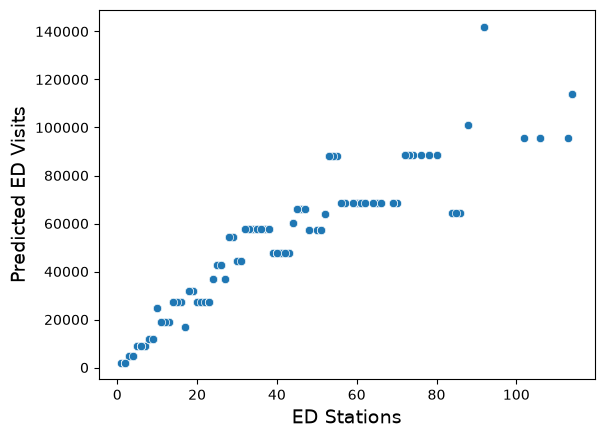

In [7]:
# Plot observed vs. predictions
p = sns.scatterplot(data=data, x="EDStations", y="pred")
p.set_xlabel("ED Stations", fontsize=14)
p.set_ylabel("Predicted ED Visits", fontsize=14)

# Calculate MSE
print(metrics.mean_squared_error(data["pred"], y))

#Calculate the Coefficient of Determination
r_squared = regtreeModelTotallyOptimal.score(X, y)
print("R^2:", r_squared)

The tuned tree raises R² on the full data from 0.683 to 0.776. The predictions now climb in many small steps instead of four. Two details show where the tree has started to fit individual hospitals rather than general patterns. First, the steps are not always increasing: EDs with 83 to 87 stations are predicted about 64,600 visits, less than EDs with 80 to 82 stations (about 88,600). Second, EDs with 91 to 97 stations are predicted about 142,000 visits, because the only hospital-years in that range belong to a single very busy hospital. These are the kinds of patterns that do not carry over to new hospitals.

Finally, we report the three required regression metrics. Because the tree was fit on all of the data, these numbers describe how well it fits hospitals it has already seen. We therefore also report the same metrics from 5-fold cross-validation, which show how it would do on hospitals it has not seen.

In [8]:
#Calculated all the model testing variables

RMSE = root_mean_squared_error(y, data["pred"])
MAE = mean_absolute_error(y, data["pred"])

print("RMSE:", RMSE)
print("MAE:", MAE)
print("R^2", r_squared)

# The same metrics on unseen data (5-fold cross-validation, same folds as the tuning step)
from sklearn.model_selection import cross_validate
cvScores = cross_validate(regtreeModelTotallyOptimal, X, y, cv=cv,
                          scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
print("\nCross-validated RMSE:", -cvScores["test_neg_root_mean_squared_error"].mean())
print("Cross-validated MAE:", -cvScores["test_neg_mean_absolute_error"].mean())
print("Cross-validated R^2:", cvScores["test_r2"].mean())

RMSE: 12758.666456460918
MAE: 8978.259092832785
R^2 0.7757286847194984

Cross-validated RMSE: 13688.411947749695
Cross-validated MAE: 9727.787898896608
Cross-validated R^2: 0.7395501238231779


On the data it was trained on, the tuned tree has an RMSE of 12,759 visits, an MAE of 8,978, and an R² of 0.776. On data it did not see during cross-validation, the RMSE rises to 13,688, the MAE to 9,728, and R² falls to 0.740. The gap between the two sets of numbers is the overfitting we expected from the steps described above, but it is modest, and the cross-validated R² still beats the straight line from Report #2 (0.687). It is also close to our 11-attribute multiple regression from Reports #2 and #3 (about 0.74), even though the tree uses only one input. Because these folds split rows rather than whole hospitals, a hospital's other years can sit in the training data, so the cross-validated figures are likely a little optimistic.

### 1.5 ED stations from location

Report #4 showed that location carried a great deal of information about a hospital. Here we ask whether latitude and longitude alone can predict how many ED stations a hospital has, following the same steps as above: a small first tree, a grid search over depth and leaves, a search over `min_samples_split`, and a final tuned tree.

|--- LATITUDE <= 32.92
|   |--- LATITUDE <= 32.72
|   |   |--- value: [27.67]
|   |--- LATITUDE >  32.72
|   |   |--- value: [77.76]
|--- LATITUDE >  32.92
|   |--- LATITUDE <= 38.84
|   |   |--- value: [28.99]
|   |--- LATITUDE >  38.84
|   |   |--- value: [13.96]



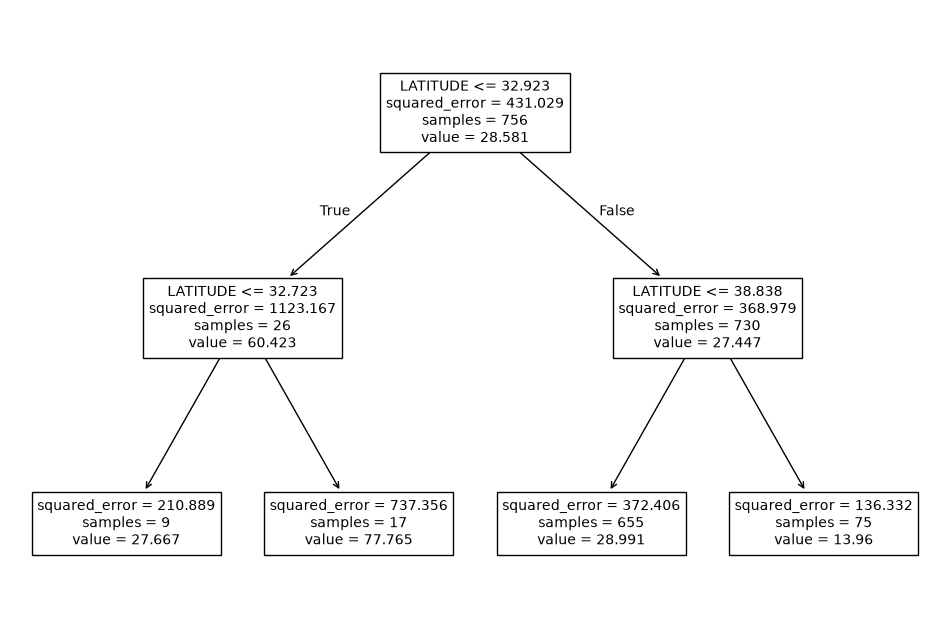

In [9]:
#Location (longitude and latitude) was useful in the unsupervised learning task, so we try it again here
#to estimate a numerical value, the number of ED stations.

#We use the same process as the previous task; the rationale is given above.

X = data[["LONGITUDE", "LATITUDE"]]
y = data[["EDStations"]]

regtreeModel2 = DecisionTreeRegressor(max_depth=2, min_samples_leaf=2, random_state=42)
regtreeModel2.fit(X, y);

print(export_text(regtreeModel2, feature_names=X.columns.to_list()))

# Using tree.plot_tree() makes a cleaner figure

# Resize the plotting window
plt.figure(figsize=[12, 8])

p = tree.plot_tree(
    regtreeModel2,
    feature_names=X.columns,
    filled=False,
    fontsize=10)

# Add the predictions to the original data set
data["pred"] = regtreeModel2.predict(X)

With only two questions, the tree splits entirely on latitude. Hospitals at or south of 32.72° are predicted about 28 stations, the narrow band between 32.72° and 32.92°, which covers central San Diego, about 78 stations, hospitals between 32.92° and 38.84° about 29 stations, and hospitals north of 38.84° about 14 stations. The large San Diego EDs and the small northern EDs are the two groups that stand out from the rest of the state.

Because this tree uses two inputs, we show its predictions on a map: each hospital is placed at its longitude and latitude and colored by the number of stations the tree predicts for it.

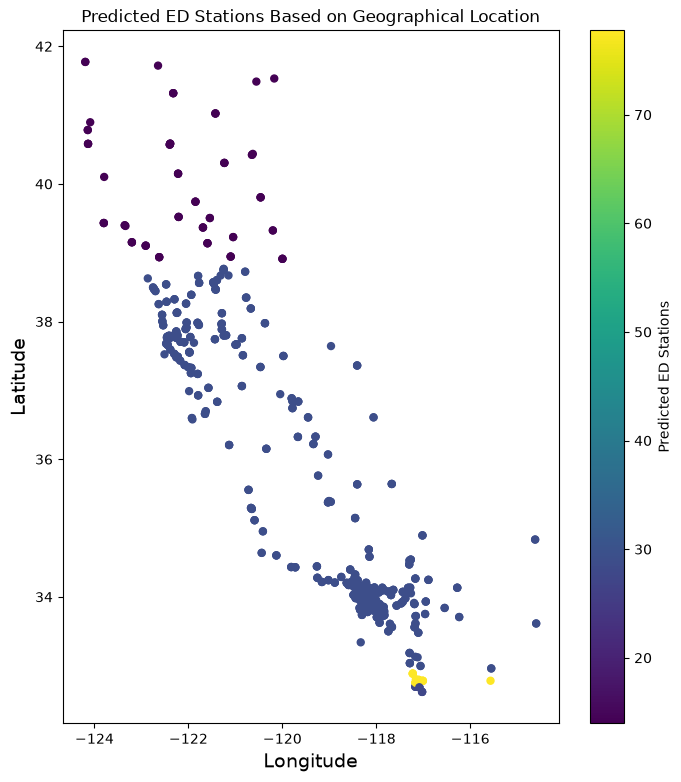

355.2696876477479
R^2: 0.17576423001301478


In [10]:
#Map of the predictions, since X has two variables
plt.figure(figsize=(8, 9))
p = plt.scatter(data["LONGITUDE"], data["LATITUDE"], c=data["pred"], cmap="viridis", s=25)
plt.colorbar(p, label="Predicted ED Stations")
plt.xlabel("Longitude", fontsize=14)
plt.ylabel("Latitude", fontsize=14)
plt.title("Predicted ED Stations Based on Geographical Location")
plt.show()

# Calculate MSE
print(metrics.mean_squared_error(data["pred"], y))

#Calculate the Coefficient of Determination
r_squared2 = regtreeModel2.score(X, y)
print("R^2:", r_squared2)

The map shows the same four groups: a bright cluster of large EDs in San Diego, small EDs across the far north, and a single middle value covering most of the state. This first tree explains only 17.6% of the variation in station counts (R² = 0.176, MSE 355.3), because it cannot tell a large Los Angeles ED from a small one a few miles away.

We repeat the grid search over depth and number of leaves for the location model.

Optimal Leaves: 40
Optimal Depth: 13
Minimum CV MSE: 247.60085937435838


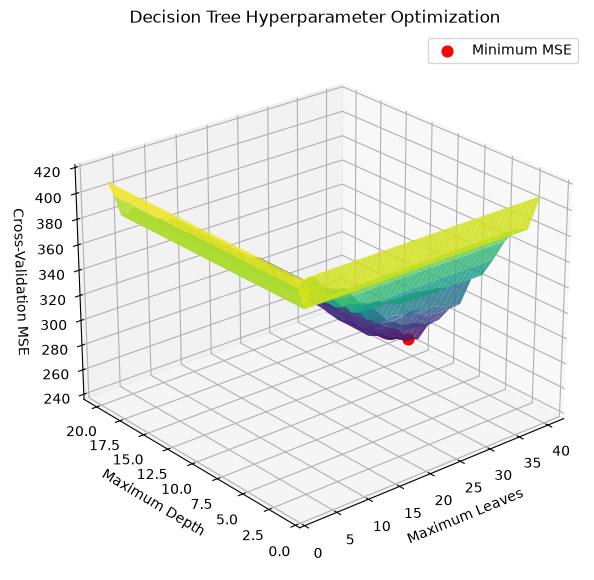

In [11]:
from sklearn.model_selection import KFold, cross_val_score

# Hyperparameter ranges
depthValues = range(1, 21)
leafValues = range(2, 41)

# Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store results
results = []

for depth in depthValues:
    for leaves in leafValues:

        model = DecisionTreeRegressor(
            max_depth=depth,
            max_leaf_nodes=leaves,
            min_samples_leaf=2,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        results.append({
            "Max_Leaves": leaves,
            "Max_Depth": depth,
            "MSE": -scores.mean()
        })

# Create results dataset
treeResults = pd.DataFrame(results)

# Find minimum error
bestRow = treeResults.loc[treeResults["MSE"].idxmin()]

print("Optimal Leaves:", int(bestRow["Max_Leaves"]))
print("Optimal Depth:", int(bestRow["Max_Depth"]))
print("Minimum CV MSE:", bestRow["MSE"])

# Convert results into a surface
surface = treeResults.pivot(
    index="Max_Depth",
    columns="Max_Leaves",
    values="MSE"
)

# 3D surface of the cross-validated error
from mpl_toolkits.mplot3d import Axes3D

leafGrid, depthGrid = np.meshgrid(surface.columns.to_numpy(), surface.index.to_numpy())
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(leafGrid, depthGrid, surface.to_numpy(), cmap="viridis", alpha=0.85)
ax.scatter([bestRow["Max_Leaves"]], [bestRow["Max_Depth"]], [bestRow["MSE"]], color="red", s=60, label="Minimum MSE")
ax.set_xlabel("Maximum Leaves")
ax.set_ylabel("Maximum Depth")
ax.set_zlabel("Cross-Validation MSE")
ax.set_title("Decision Tree Hyperparameter Optimization")
ax.view_init(elev=25, azim=-130)
ax.legend()
plt.show()

The lowest cross-validated MSE, about 247.6 (an RMSE of roughly 15.7 stations), comes from a maximum depth of 13 and 40 leaves. Unlike the visits model, the surface keeps sloping down toward the edge of the search: 40 is the largest number of leaves we tried. A location tree needs many small regions to separate nearby hospitals, so it keeps improving as it gets more leaves, which is also a sign that it is learning individual locations rather than broad regional patterns.

Then we repeat the search for the best `min_samples_split`.

New starting point: 5 | Step size: 15 | MSE: 248.77637204578906
New starting point: 2 | Step size: 3 | MSE: 247.60085937435838

Optimal min_samples_split: 2
Minimum CV MSE found: 247.60085937435838


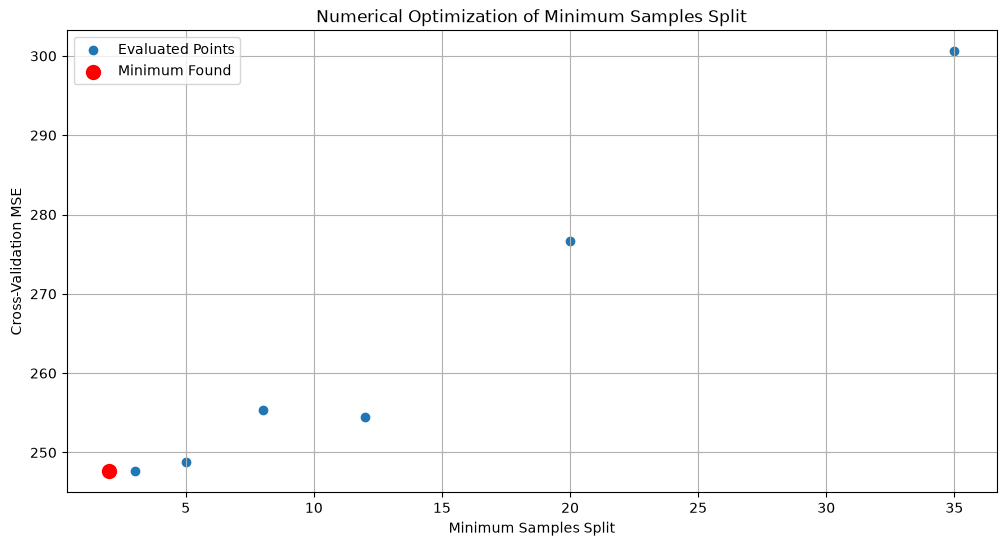

In [12]:
# Keep previously optimized hyperparameters
bestDepth = int(bestRow["Max_Depth"])
bestLeaves = int(bestRow["Max_Leaves"])

# Use the same cross-validation procedure
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Store evaluated values to avoid redundant calculations
splitErrors = {}

# Define the error function
def calculateError(s):

    if s not in splitErrors:

        model = DecisionTreeRegressor(
            max_depth=bestDepth,
            max_leaf_nodes=bestLeaves,
            min_samples_leaf=2,
            min_samples_split=s,
            random_state=42
        )

        scores = cross_val_score(
            model, X, y,
            cv=cv,
            scoring="neg_mean_squared_error"
        )

        splitErrors[s] = -scores.mean()

    return splitErrors[s]

# Initial starting point and step size
s = 20
h = 15

# Numerical optimization
while h >= 1:

    while True:

        # Evaluate the current point and its neighbors
        candidates = [s]

        if s - h >= 2:
            candidates.append(s - h)

        if s + h <= len(X):
            candidates.append(s + h)

        # Find the candidate with the lowest error
        newS = min(candidates, key=calculateError)

        # Move only if the error strictly decreases
        if calculateError(newS) < calculateError(s):
            s = newS

            print("New starting point:", s,
                  "| Step size:", h,
                  "| MSE:", calculateError(s))

        else:
            break

    # Reduce the step size
    h = h // 2

# Final results
bestSplit = s

print("\nOptimal min_samples_split:", bestSplit)
print("Minimum CV MSE found:", calculateError(bestSplit))

# Create a dataset of evaluated points
splitResults = pd.DataFrame({
    "Min_Samples_Split": list(splitErrors.keys()),
    "MSE": list(splitErrors.values())
})

splitResults = splitResults.sort_values("Min_Samples_Split")

# Plot the evaluated points
plt.figure(figsize=(12, 6))

plt.scatter(
    splitResults["Min_Samples_Split"],
    splitResults["MSE"],
    label="Evaluated Points"
)

plt.scatter(
    bestSplit,
    calculateError(bestSplit),
    color="red",
    s=100,
    label="Minimum Found"
)

plt.xlabel("Minimum Samples Split")
plt.ylabel("Cross-Validation MSE")
plt.title("Numerical Optimization of Minimum Samples Split")
plt.legend()
plt.grid()
plt.show()

As before, the search settled on the default `min_samples_split` of 2, with the same minimum error of 247.6. The leaf-size and leaf-count limits already control the tree's size.

We fit the tuned location tree. The text version shows every split; the diagram shows the top three levels.

|--- LATITUDE <= 32.92
|   |--- LATITUDE <= 32.72
|   |   |--- LONGITUDE <= -117.05
|   |   |   |--- value: [17.50]
|   |   |--- LONGITUDE >  -117.05
|   |   |   |--- value: [48.00]
|   |--- LATITUDE >  32.72
|   |   |--- LATITUDE <= 32.80
|   |   |   |--- LONGITUDE <= -117.01
|   |   |   |   |--- LONGITUDE <= -117.13
|   |   |   |   |   |--- value: [80.80]
|   |   |   |   |--- LONGITUDE >  -117.13
|   |   |   |   |   |--- value: [111.40]
|   |   |   |--- LONGITUDE >  -117.01
|   |   |   |   |--- value: [47.00]
|   |   |--- LATITUDE >  32.80
|   |   |   |--- value: [53.40]
|--- LATITUDE >  32.92
|   |--- LATITUDE <= 38.84
|   |   |--- LATITUDE <= 38.74
|   |   |   |--- LONGITUDE <= -117.11
|   |   |   |   |--- LATITUDE <= 33.66
|   |   |   |   |   |--- LATITUDE <= 33.62
|   |   |   |   |   |   |--- LONGITUDE <= -117.69
|   |   |   |   |   |   |   |--- value: [20.67]
|   |   |   |   |   |   |--- LONGITUDE >  -117.69
|   |   |   |   |   |   |   |--- value: [48.69]
|   |   |   |   |   |--

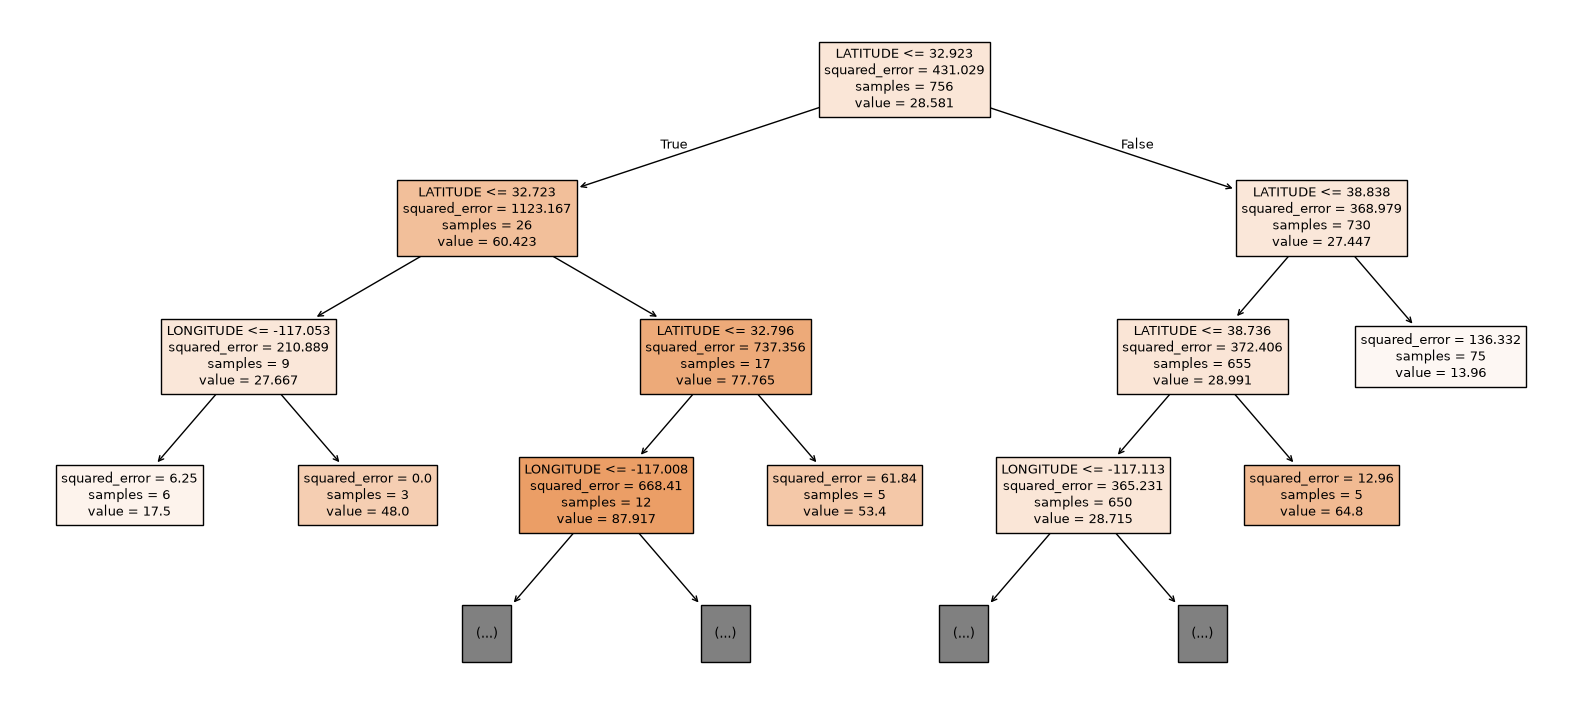

In [13]:
#New completley optimized regression tree

#Using the optimal, this is the new regression tree.

regtreeModelTotallyOptimal1 = DecisionTreeRegressor(max_depth=bestDepth, max_leaf_nodes=bestLeaves,
                                                    min_samples_leaf=2, min_samples_split=bestSplit, random_state=42)
regtreeModelTotallyOptimal1.fit(X, y);

print(export_text(regtreeModelTotallyOptimal1, feature_names=X.columns.to_list()))

# Add the predictions to the original data set
data["pred"] = regtreeModelTotallyOptimal1.predict(X)

plt.figure(figsize=[20, 9])

p = tree.plot_tree(
    regtreeModelTotallyOptimal1,
    feature_names=X.columns,
    max_depth=3,
    filled=True,
    fontsize=9)

The tuned tree uses 40 small regions defined by latitude and longitude. Its top levels follow the first tree, then carve San Diego and the rest of the state into finer pieces. For example, within San Diego it separates a group of 5 hospital-years averaging about 111 stations from a neighboring group averaging about 81.

As in 1.4, we report the regression metrics on the full data and with 5-fold cross-validation.

In [14]:
#Calculated all the model testing variables

RMSE = root_mean_squared_error(y, data["pred"])
MAE = mean_absolute_error(y, data["pred"])
r_squared = regtreeModelTotallyOptimal1.score(X, y)

print("RMSE:", RMSE)
print("MAE:", MAE)
print("R^2", r_squared)

# The same metrics on unseen data (5-fold cross-validation)
cvScores = cross_validate(regtreeModelTotallyOptimal1, X, y, cv=cv,
                          scoring=("r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"))
print("\nCross-validated RMSE:", -cvScores["test_neg_root_mean_squared_error"].mean())
print("Cross-validated MAE:", -cvScores["test_neg_mean_absolute_error"].mean())
print("Cross-validated R^2:", cvScores["test_r2"].mean())

RMSE: 12.62901367648013
MAE: 9.688880216131855
R^2 0.6299740596471466

Cross-validated RMSE: 15.724994836106504
Cross-validated MAE: 11.29438108713785
Cross-validated R^2: 0.41753374194630144


On the training data, the location tree has an RMSE of 12.6 stations, an MAE of 9.7, and an R² of 0.630. On data it did not see, the RMSE rises to 15.7, the MAE to 11.3, and R² drops to 0.418. That large gap is a clear sign of overfitting: about a third of the apparent fit comes from memorizing where particular hospitals are. Location carries some real information about ED size, explaining roughly 42% of the variation in new data, but it is far weaker than the station-and-visit relationship in Section 1.4. Because a hospital's coordinates appear in every year it reports, row-level folds let the tree see a hospital's location during training before predicting it, so even 0.418 is probably optimistic.

## 2. Decision Tree Classification

Task: build and train a Decision Tree Classifier, evaluate it with a confusion matrix, accuracy, precision, recall, and F1-score, visualize the tree's splits, and discuss the features that drive its classifications.

A classification tree works like the regression tree, except each leaf predicts a class instead of a number: a new hospital follows the yes/no questions down to a leaf and receives the most common class among the training hospitals in that leaf. The tree chooses each question to make the groups as pure as possible, measured by Gini impurity.

We present two classification tasks. Section 2.1 predicts whether a hospital is urban, the main model for this report. Section 2.2 follows our original plan of predicting whether a hospital is a teaching hospital, and shows why that task is much harder.

### 2.1 Urban designation

**Target:** urban (1) vs. rural or frontier (0). We studied the same target in Reports #3 and #4, so we have earlier results to compare against: logistic regression reached 90.2% accuracy and the Support Vector Machine reached 91.4%.

**Features:** six numerical attributes: ED stations, bed size rank, total ED visits, ED burden, latitude, and longitude. Trees do not need the features to be on the same scale, so no standardization is required.

**Evaluation design:** most hospitals appear in two or three years with nearly the same values. If rows were split at random, the same hospital could land in both training and testing. We therefore hold out 25% of the hospitals (all of their years) as a test set and do all tuning with 5-fold cross-validation inside the remaining hospitals, keeping each hospital in a single fold. The hospitals are assigned with a fixed random seed, the same assignment used in Report #4, so the split is identical on every computer.

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import PredefinedSplit, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, classification_report, ConfusionMatrixDisplay)

CLASS_FEATURES = ["EDStations", "Bed_Size_Rank", "Tot_ED_NmbVsts", "ED_Burden", "LAT_STD", "LON_STD"]
X_cls = data[CLASS_FEATURES]
y_urban = (data["UrbanRuralDesi"] == "Urban").astype(int)

# Hold out 25% of hospitals (all of their years) as the final test set
hospitals = np.sort(data["oshpd_id"].unique())
shuffled = np.random.RandomState(42).permutation(hospitals)
test_hospitals = set(shuffled[: len(hospitals) // 4])
is_test = data["oshpd_id"].isin(test_hospitals).to_numpy()

Xc_train, Xc_test = X_cls[~is_test], X_cls[is_test]
yc_train, yc_test = y_urban[~is_test], y_urban[is_test]

# Five folds within the training hospitals, keeping each hospital in one fold
train_hospitals = [h for h in shuffled if h not in test_hospitals]
fold_of = {h: i % 5 for i, h in enumerate(train_hospitals)}
cv_group = PredefinedSplit(data.loc[~is_test, "oshpd_id"].map(fold_of).to_numpy())

print(f"Training set: {len(Xc_train)} rows from {len(train_hospitals)} hospitals")
print(f"Test set:     {len(Xc_test)} rows from {len(test_hospitals)} hospitals")
print("Hospitals in both sets:", len(set(train_hospitals) & test_hospitals))
print(f"Urban share: training {yc_train.mean():.3f}, test {yc_test.mean():.3f}")
print(f"No-skill accuracy on the test set (always guess urban): {yc_test.mean():.3f}")

Training set: 570 rows from 223 hospitals
Test set:     186 rows from 74 hospitals
Hospitals in both sets: 0
Urban share: training 0.775, test 0.790
No-skill accuracy on the test set (always guess urban): 0.790


The training set has 570 rows from 223 hospitals and the test set has 186 rows from 74 hospitals, with no hospital in both. These are the same 74 test hospitals used in Report #4, so the results can be compared directly with the SVM. Urban hospitals make up 77.5% of training and 79.0% of testing, so a rule that always guessed "urban" would be right 79.0% of the time. Any useful model has to beat that.

#### 2.1.1 An unpruned tree: what overfitting looks like

Before tuning, we grow a tree with no limits on depth or leaf size. It keeps splitting until every leaf is pure, so it can memorize the training hospitals. Comparing its training and test accuracy shows how much of that memorization carries over to new hospitals.

In [16]:
fullTree = DecisionTreeClassifier(random_state=42).fit(Xc_train, yc_train)

print("Depth:", fullTree.get_depth(), "| Leaves:", fullTree.get_n_leaves())
print(f"Training accuracy: {accuracy_score(yc_train, fullTree.predict(Xc_train)):.3f}")
print(f"Test accuracy:     {accuracy_score(yc_test, fullTree.predict(Xc_test)):.3f}")
print(f"Test F1-score:     {f1_score(yc_test, fullTree.predict(Xc_test)):.3f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(yc_test, fullTree.predict(Xc_test)):.3f}")

# The same unpruned tree, scored across the five hospital-grouped folds of the training data
from sklearn.model_selection import cross_val_score
fullFolds = cross_val_score(DecisionTreeClassifier(random_state=42), Xc_train, yc_train,
                            cv=cv_group, scoring="balanced_accuracy")
print("Cross-validated balanced accuracy by fold:", np.round(fullFolds, 3))
print(f"Cross-validated balanced accuracy (mean): {fullFolds.mean():.3f}")

Depth: 10 | Leaves: 25
Training accuracy: 1.000
Test accuracy:     0.935
Test F1-score:     0.959
Test balanced accuracy: 0.893
Cross-validated balanced accuracy by fold: [0.72  0.741 0.967 0.739 0.879]
Cross-validated balanced accuracy (mean): 0.809


Left unchecked, the tree grows 10 levels deep with 25 leaves and classifies every training hospital correctly (training accuracy 1.000). On the 74 test hospitals it does well too, with 93.5% accuracy and a balanced accuracy of 0.893. Across the five grouped folds, however, its balanced accuracy swings from 0.720 to 0.967 and averages only 0.809. In other words, the unpruned tree is unstable: depending on which hospitals it trains on, it can do very well or quite poorly, and our particular test set happened to fall on the favorable side. A single test set of 74 hospitals is too small to judge a model on its own, which is why we tune with cross-validation.

#### 2.1.2 Tuning the tree

We search over three settings with `GridSearchCV`, using the hospital-grouped folds:

- `max_depth`: how many questions deep the tree may go (2 to 8, or unlimited).
- `min_samples_leaf`: the fewest training rows allowed in a leaf (1, 5, 10, or 20). Larger values force broader, more general leaves.
- `class_weight`: none, or balanced, which makes mistakes on the smaller rural/frontier class count more.

Each combination is scored by balanced accuracy, the average of the accuracy within each class, because about 78% of the hospitals are urban and plain accuracy would reward a tree that leans too heavily toward "urban." The heat map shows the cross-validated score for each depth and leaf size, with the better class-weight option for each cell.

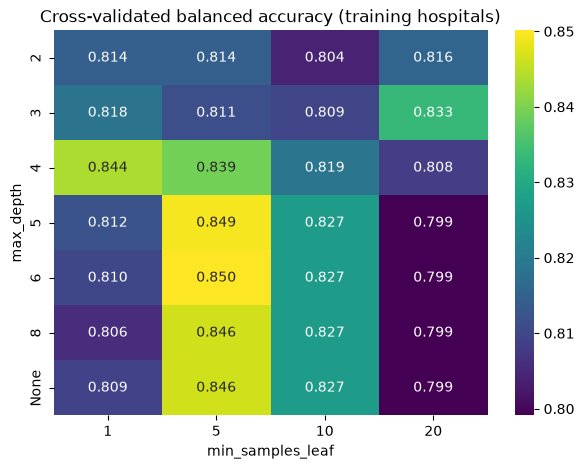

Best settings: {'class_weight': None, 'max_depth': 6, 'min_samples_leaf': 5}
Best cross-validated balanced accuracy: 0.85


In [17]:
param_grid = {"max_depth": [2, 3, 4, 5, 6, 8, None],
              "min_samples_leaf": [1, 5, 10, 20],
              "class_weight": [None, "balanced"]}
treeSearch = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                          cv=cv_group, scoring="balanced_accuracy")
treeSearch.fit(Xc_train, yc_train)

grid = pd.DataFrame(treeSearch.cv_results_)
grid["Depth"] = grid["param_max_depth"].astype(object).where(grid["param_max_depth"].notna(), "None").astype(str)
heat = grid.groupby(["Depth", "param_min_samples_leaf"])["mean_test_score"].max().unstack()
heat = heat.reindex(["2", "3", "4", "5", "6", "8", "None"])

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set(title="Cross-validated balanced accuracy (training hospitals)", xlabel="min_samples_leaf", ylabel="max_depth")
plt.show()

print("Best settings:", treeSearch.best_params_)
print("Best cross-validated balanced accuracy:", round(treeSearch.best_score_, 3))

The best combination is a maximum depth of 6 and at least 5 rows per leaf, without class weights, with a cross-validated balanced accuracy of 0.850, noticeably higher than the unpruned tree's 0.809. The heat map shows that the leaf size matters more than the depth. A minimum of 5 rows per leaf gives the best results at every depth from 4 up, while requiring only 1 row per leaf lets the tree chase individual hospitals, and requiring 20 makes it too coarse, dropping deep trees to about 0.80. Depths of 2 and 3 score lower because the tree cannot ask enough questions.

#### 2.1.3 Evaluating the tuned tree on unseen hospitals

We now score the tuned tree once on the held-out hospitals and report every required measure. For each class:

- Precision: of the hospitals the tree assigned to this class, the share that truly belong to it.
- Recall: of the hospitals that truly belong to this class, the share the tree found.
- F1-score: the balance (harmonic mean) of precision and recall.

Accuracy:            0.914  (no-skill: 0.790)
Balanced accuracy:   0.823
Precision (urban):   0.917
Recall (urban):      0.980
F1-score (urban):    0.947
Training accuracy:   0.963

Classification report:
                precision    recall  f1-score   support

Rural/frontier      0.897     0.667     0.765        39
         Urban      0.917     0.980     0.947       147

      accuracy                          0.914       186
     macro avg      0.907     0.823     0.856       186
  weighted avg      0.913     0.914     0.909       186



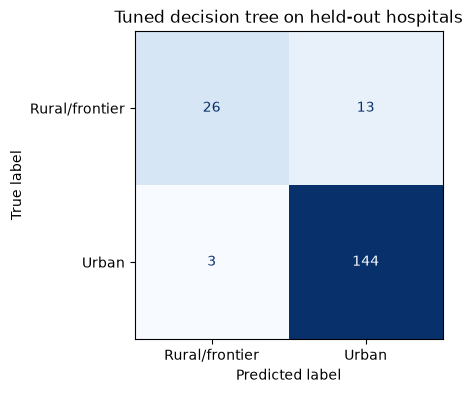

In [18]:
bestTree = treeSearch.best_estimator_
tree_pred = bestTree.predict(Xc_test)

print(f"Accuracy:            {accuracy_score(yc_test, tree_pred):.3f}  (no-skill: {yc_test.mean():.3f})")
print(f"Balanced accuracy:   {balanced_accuracy_score(yc_test, tree_pred):.3f}")
print(f"Precision (urban):   {precision_score(yc_test, tree_pred):.3f}")
print(f"Recall (urban):      {recall_score(yc_test, tree_pred):.3f}")
print(f"F1-score (urban):    {f1_score(yc_test, tree_pred):.3f}")
print(f"Training accuracy:   {accuracy_score(yc_train, bestTree.predict(Xc_train)):.3f}")
print("\nClassification report:")
print(classification_report(yc_test, tree_pred, target_names=["Rural/frontier", "Urban"], digits=3))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(yc_test, tree_pred, display_labels=["Rural/frontier", "Urban"],
                                        cmap="Blues", colorbar=False, ax=ax)
ax.set_title("Tuned decision tree on held-out hospitals")
plt.show()

On the 74 held-out hospitals, the tuned tree classifies 91.4% of hospital-years correctly, well above the 79.0% no-skill rate, with 16 errors out of 186. For the urban class, precision is 0.917, recall is 0.980, and F1 is 0.947: when the tree says "urban" it is right about 92% of the time, and it finds 98% of the urban hospitals. The rural/frontier class is harder. Precision is high (0.897) but recall is 0.667, so the tree finds only 26 of the 39 rural or frontier hospital-years and labels the other 13 as urban. Its training accuracy (0.963) is close to its test accuracy, so the pruned tree generalizes much more consistently than the unpruned one.

For comparison, on these same test hospitals the SVM from Report #4 also reached 91.4% accuracy, with a higher balanced accuracy of 0.880, and logistic regression reached 90.3%. The tree matches the SVM's overall accuracy but is weaker on the smaller rural group. Its advantage is that, unlike the SVM, it can be read and explained, as the next step shows.

#### 2.1.4 Visualizing the splits

The diagram shows the tuned tree's top three levels. Each box lists the question asked, the Gini impurity (0 means the node is pure), the number of training rows that reach it, the count of rural/frontier and urban rows, and the majority class. Orange boxes lean rural/frontier and blue boxes lean urban; darker colors mean purer groups. Latitude and longitude appear as `LAT_STD` and `LON_STD`, in degrees.

Depth: 6 | Leaves: 17


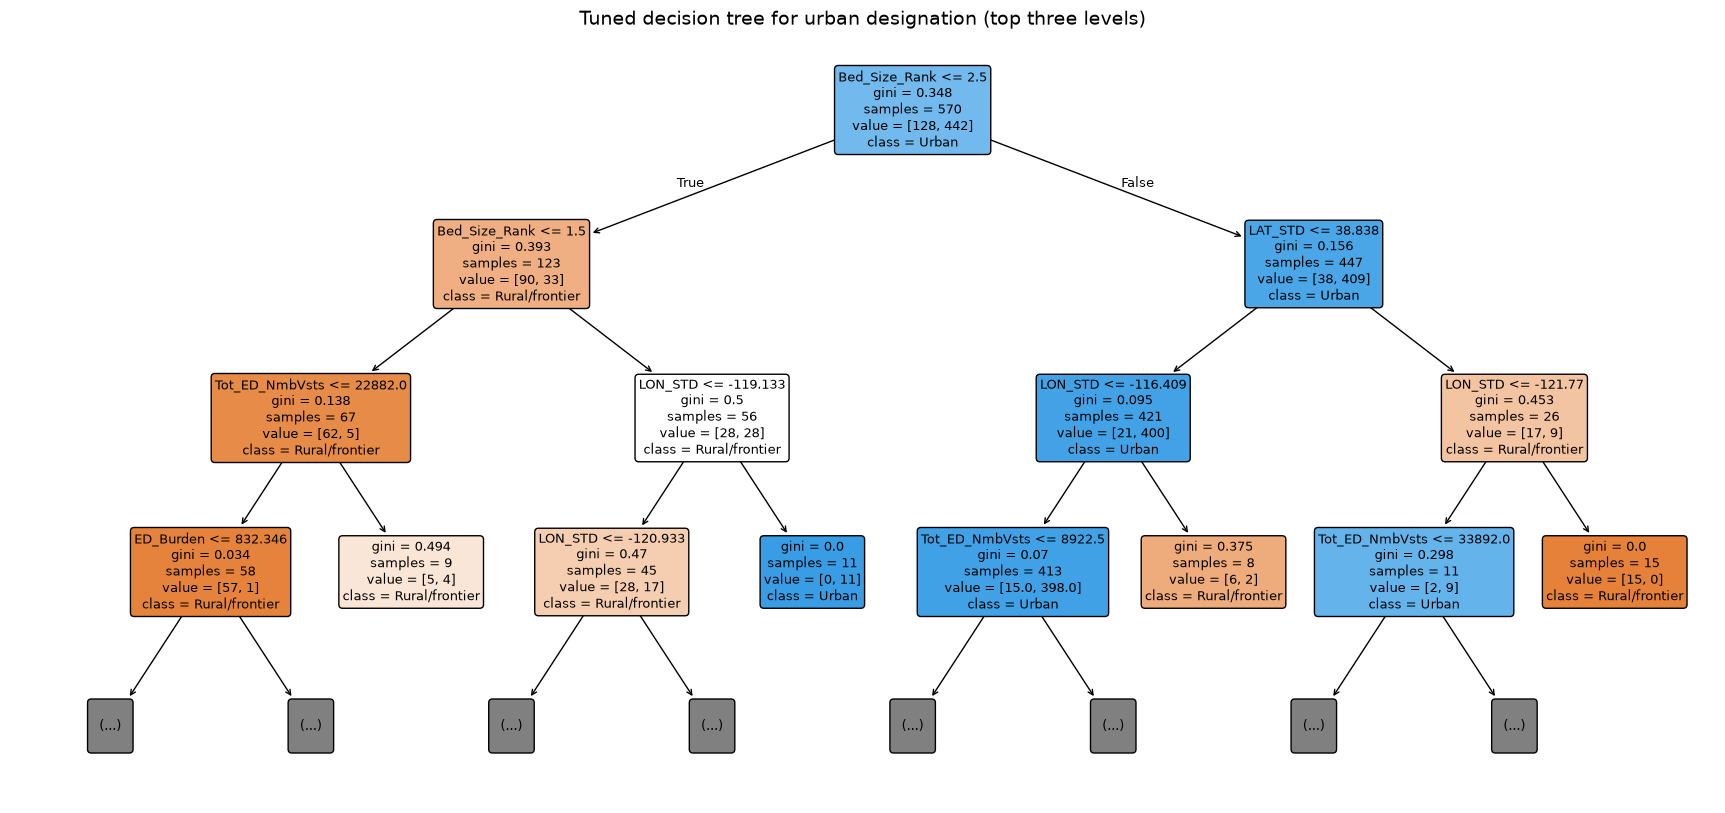

|--- Bed_Size_Rank <= 2.50
|   |--- Bed_Size_Rank <= 1.50
|   |   |--- Tot_ED_NmbVsts <= 22882.00
|   |   |   |--- ED_Burden <= 832.35
|   |   |   |   |--- class: 0
|   |   |   |--- ED_Burden >  832.35
|   |   |   |   |--- class: 0
|   |   |--- Tot_ED_NmbVsts >  22882.00
|   |   |   |--- class: 0
|   |--- Bed_Size_Rank >  1.50
|   |   |--- LON_STD <= -119.13
|   |   |   |--- LON_STD <= -120.93
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- LON_STD >  -120.93
|   |   |   |   |--- class: 0
|   |   |--- LON_STD >  -119.13
|   |   |   |--- class: 1
|--- Bed_Size_Rank >  2.50
|   |--- LAT_STD <= 38.84
|   |   |--- LON_STD <= -116.41
|   |   |   |--- Tot_ED_NmbVsts <= 8922.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Tot_ED_NmbVsts >  8922.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- LON_STD >  -116.41
|   |   |   |--- class: 0
|   |--- LAT_STD >  38.84
|   |   |--- LON_STD <= -121.77
|   |   |   |--- Tot_ED_NmbVsts <= 33892.00
|

In [19]:
print("Depth:", bestTree.get_depth(), "| Leaves:", bestTree.get_n_leaves())

plt.figure(figsize=(22, 10))
tree.plot_tree(bestTree, feature_names=CLASS_FEATURES, class_names=["Rural/frontier", "Urban"],
               filled=True, rounded=True, max_depth=3, fontsize=9, impurity=True)
plt.title("Tuned decision tree for urban designation (top three levels)", fontsize=14)
plt.show()

print(export_text(bestTree, feature_names=CLASS_FEATURES, max_depth=3, decimals=2))

The tuned tree is 6 levels deep with 17 leaves. Its logic is easy to follow:

1. The first question is bed size. Hospitals with a bed size rank of 2 or less (fewer than 100 licensed beds) go left, where 90 of 123 training rows are rural or frontier. Larger hospitals go right, where 409 of 447 rows are urban.
2. Among the small hospitals, those with fewer than 50 beds are almost all rural or frontier (62 of 67 rows). For hospitals with 50 to 99 beds, the group is split evenly (28 and 28), and the tree turns to longitude: those east of about −119.1°, in the Los Angeles and Inland Empire region, are all urban (11 of 11).
3. Among the larger hospitals, location settles most cases. Those south of about 38.8° latitude are overwhelmingly urban (400 of 421). North of that line, those west of about −121.8° are all rural (15 of 15), and those in the far eastern desert (east of about −116.4°) lean rural.

In short, the tree first asks "is this a small hospital?" and then "is it in one of California's metropolitan regions?", which is how a person familiar with the state might reason.

#### 2.1.5 Which features drive the classifications?

A tree's feature importance measures how much each feature reduces Gini impurity across all of the splits that use it, scaled so the importances add up to 1. A feature the tree never uses has an importance of 0.

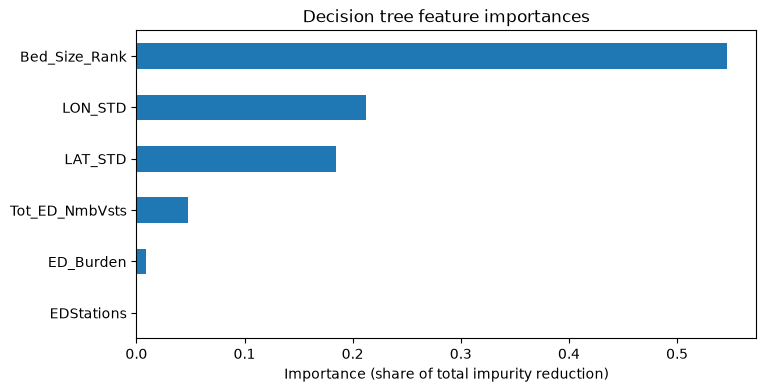

Bed_Size_Rank     0.546
LON_STD           0.213
LAT_STD           0.185
Tot_ED_NmbVsts    0.048
ED_Burden         0.009
EDStations        0.000


In [20]:
treeImportance = pd.Series(bestTree.feature_importances_, index=CLASS_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
treeImportance.plot.barh(ax=ax, color="tab:blue")
ax.set(xlabel="Importance (share of total impurity reduction)", title="Decision tree feature importances")
plt.show()

print(treeImportance.sort_values(ascending=False).round(3).to_string())

Bed size rank is by far the most influential feature, accounting for 54.6% of the impurity reduction, followed by longitude (21.3%) and latitude (18.5%). Together, location contributes about 40%. Total visits play a small role (4.8%), ED burden almost none (0.9%), and ED stations none at all. That does not mean stations are unrelated to setting. Stations, beds, and visits all measure hospital size and are strongly correlated, so once the tree has split on bed size, stations add no new information, and the tree never chooses them. A single tree tends to pick one of several related features and ignore the rest, a point we return to in Section 3.2.

### 2.2 Teaching designation: the harder task

Our original plan for this section was to predict whether a hospital is a teaching hospital. In Report #2, a logistic regression on station count was our best attempt at this target, and it was not good. Here we test whether a decision tree does better, in three steps:

1. Teaching status from ED stations alone.
2. Teaching status from ED stations and ED burden.
3. The same two features, but only for urban hospitals. Before running this step we checked the data: all 73 teaching hospital-years are urban and none are rural or frontier, so a separate non-urban model is impossible and the urban subset is the only meaningful partition.

Teaching hospitals are only about 10% of the data, so each tree is tuned with balanced class weights allowed and scored by F1-score for the teaching class. We use the same held-out hospitals and folds as Section 2.1.

In [21]:
y_teach = (data["TEACHINGDesignation"] == "Teaching").astype(int)
print(pd.crosstab(data["UrbanRuralDesi"], data["TEACHINGDesignation"]))

teach_grid = {"max_depth": [2, 3, 4, 5, 6], "min_samples_leaf": [1, 5, 10, 20],
              "class_weight": [None, "balanced"]}
urban_rows = (data["UrbanRuralDesi"] == "Urban").to_numpy()
experiments = {
    "Stations only, all hospitals": (["EDStations"], np.ones(len(data), dtype=bool)),
    "Stations + burden, all hospitals": (["EDStations", "ED_Burden"], np.ones(len(data), dtype=bool)),
    "Stations + burden, urban hospitals only": (["EDStations", "ED_Burden"], urban_rows),
}
teachRows, teachModels = {}, {}
for name, (features, keep) in experiments.items():
    train_mask, test_mask = keep & ~is_test, keep & is_test
    folds = data.loc[train_mask, "oshpd_id"].map(fold_of).to_numpy()
    search = GridSearchCV(DecisionTreeClassifier(random_state=42), teach_grid,
                          cv=PredefinedSplit(folds), scoring="f1")
    search.fit(data.loc[train_mask, features], y_teach[train_mask])
    pred = search.predict(data.loc[test_mask, features])
    y_true = y_teach[test_mask]
    teachModels[name] = (search.best_estimator_, features, test_mask)
    teachRows[name] = {"Test rows": int(test_mask.sum()),
                       "Teaching in test": int(y_true.sum()),
                       "Accuracy": accuracy_score(y_true, pred),
                       "No-skill accuracy": 1 - y_true.mean(),
                       "Precision": precision_score(y_true, pred, zero_division=0),
                       "Recall": recall_score(y_true, pred),
                       "F1-score": f1_score(y_true, pred)}
display(pd.DataFrame(teachRows).T.round(3))

TEACHINGDesignation  Non-Teaching  Teaching
UrbanRuralDesi                             
Frontier                       23         0
Rural                         144         0
Urban                         516        73


,Test rows,Teaching in test,Accuracy,No-skill accuracy,Precision,Recall,F1-score
"Stations only, all hospitals",186.0,19.0,0.796,0.898,0.212,0.368,0.269
"Stations + burden, all hospitals",186.0,19.0,0.801,0.898,0.179,0.263,0.213
"Stations + burden, urban hospitals only",147.0,19.0,0.769,0.871,0.200,0.263,0.227


The crosstab confirms that all 73 teaching hospital-years are urban, so restricting to urban hospitals is the only partition that can be tested.

None of the three trees beats the simplest possible rule. Always guessing "non-teaching" would be right 89.8% of the time on the full test set (87.1% for urban hospitals only), but the trees reach only 76.9% to 80.1% accuracy. Because the trees were tuned to find teaching hospitals, they flag many hospitals as teaching, and most of those flags are wrong: precision ranges from 0.179 to 0.212. They also miss most of the 19 teaching hospital-years in the test set, with recall between 0.263 and 0.368. The best result, an F1-score of 0.269, comes from station count alone, and adding burden or limiting the data to urban hospitals does not help.

To see why the task is difficult, we plot the two features for every hospital, marking teaching hospitals separately, and draw the confusion matrix for the stations-and-burden tree.

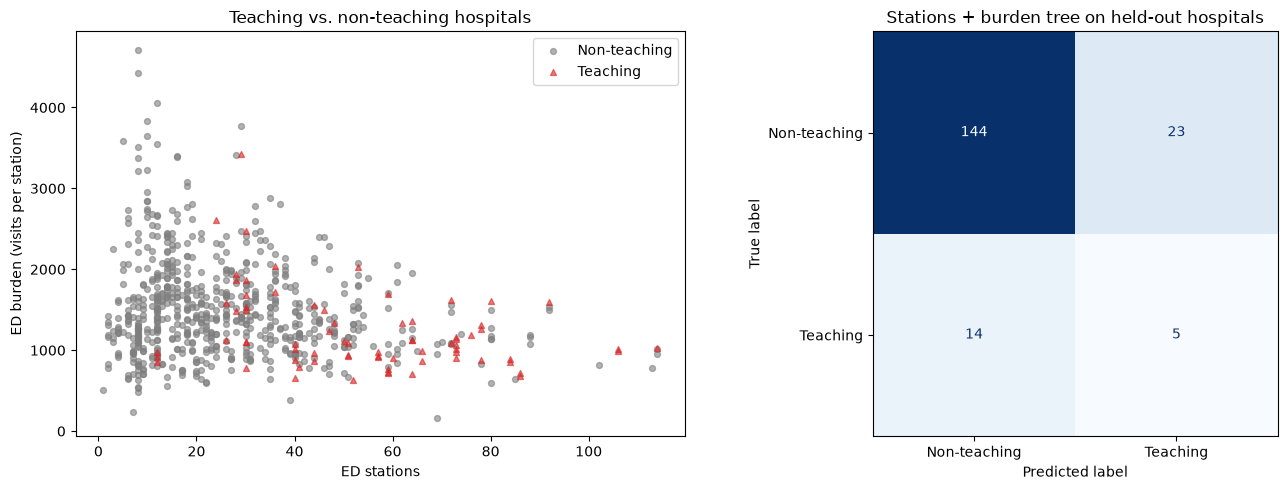

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for value, label, color, marker in [(0, "Non-teaching", "tab:gray", "o"), (1, "Teaching", "tab:red", "^")]:
    pts = data[y_teach == value]
    axes[0].scatter(pts["EDStations"], pts["ED_Burden"], c=color, marker=marker, s=18, alpha=0.6, label=label)
axes[0].set(xlabel="ED stations", ylabel="ED burden (visits per station)", title="Teaching vs. non-teaching hospitals")
axes[0].legend()

model, features, test_mask = teachModels["Stations + burden, all hospitals"]
ConfusionMatrixDisplay.from_predictions(y_teach[test_mask], model.predict(data.loc[test_mask, features]),
                                        display_labels=["Non-teaching", "Teaching"], cmap="Blues",
                                        colorbar=False, ax=axes[1])
axes[1].set_title("Stations + burden tree on held-out hospitals")
plt.tight_layout()
plt.show()

The scatter plot shows why. Teaching hospitals (red) are spread across nearly the whole range of station counts and burden, mixed in with non-teaching hospitals (gray). They lean toward the larger EDs, which is what the logistic regression in Report #2 picked up, but there are many large non-teaching EDs and some small teaching ones. No set of yes/no questions about these two features can draw a boundary around them. The confusion matrix makes the cost concrete: the tree finds 5 of the 19 teaching hospital-years and raises 23 false alarms. Teaching status depends on things our dataset does not record, such as medical school affiliations and residency programs, so this task is not one a decision tree can solve with these features.

## 3. Random Forest (Ensemble Learning)

Task: apply a Random Forest to the same tasks as above, and compare its performance, generalization, and feature-importance rankings against the single decision tree.

A Random Forest builds many decision trees, each trained on a bootstrap sample of the data (rows drawn at random with replacement) and, at each split, allowed to consider only a random subset of the features. The forest's prediction is the average of the trees for regression, or the majority vote for classification. Because the trees make different mistakes, averaging them usually reduces the variance that makes a single deep tree overfit.

### 3.1 Random Forest regression: total ED visits from ED stations

We start with the regression task from Section 1.1, using a 70/30 train-test split. The first forest is small (two levels deep, default number of trees) so we have a starting point.

MSE:  175125574.4168326
R^2: 0.710143877543697
R^2 Trained: 0.6990983472341525
R^2 Tested: 0.7386022524385322


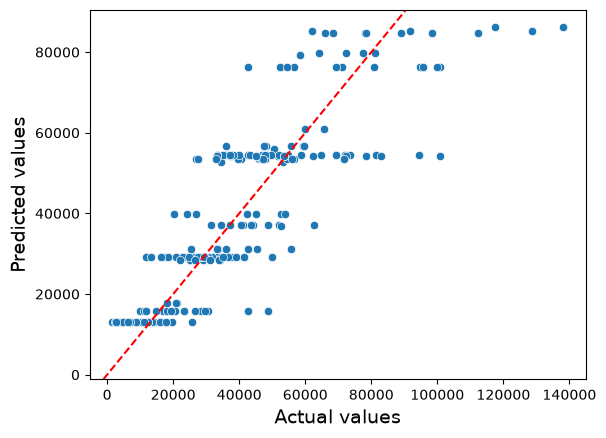

In [23]:
#Regression, 1. Trying to beat the optimized regression tree with EDStations and Total ED Visits

X = data[["EDStations"]]
y = data["Tot_ED_NmbVsts"]

# Create a training/testing split
# 30% of instances held out for testing
# 70% of instances used for training
#We use random_state = 42 for the sake of reproducability
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state= 42)

# Define a regression random forest model
rfModel = RandomForestRegressor(max_depth=2, max_features="sqrt", random_state=99)

# Fit the model
rfModel.fit(X_train, y_train);

# Predict ED visits on the testing data
y_pred = rfModel.predict(X_test)

# Compare testing predictions to actual values
p = sns.scatterplot(x=y_test, y=y_pred)
p.set_xlabel("Actual values", fontsize=14)
p.set_ylabel("Predicted values", fontsize=14)

# Add a diagonal line
# If the testing predictions are close to the actual values,
# points should fall along this line
plt.axline((3000, 3000), (6000, 6000), color="r", ls="--")

# Print mean squared error (MSE)
print("MSE: ", metrics.mean_squared_error(y_test, y_pred))

#R^2 calculation
r_squared = rfModel.score(X, y)
print("R^2:", r_squared)
r_squaredTrain = rfModel.score(X_train, y_train)
print("R^2 Trained:", r_squaredTrain)
r_squaredTest = rfModel.score(X_test, y_test)
print("R^2 Tested:", r_squaredTest)

The first forest explains 73.9% of the variation in visits on the test set (R² = 0.739, MSE about 175.1 million) and 69.9% on the training set. Because each tree is only two levels deep, the forest can return only a limited set of values, which is why the predictions form horizontal bands in the plot. The test score being slightly higher than the training score means this forest is not overfitting; if anything, it is too simple.

#### 3.1.1 How many trees are enough?

Adding trees never makes a Random Forest overfit, but past some point extra trees only add computing time. To find that point, we grow the forest 10 trees at a time and compare its predictions across the last 100 trees added. When the largest change in any prediction over that window drops below a tolerance (63 visits), the forest has converged, and we keep the smallest number of trees that meets the test. The search stops at 5,000 trees if it never converges.

Convergence achieved!
Optimal number of estimators: 2470
Final maximum difference: 62.667646916612284


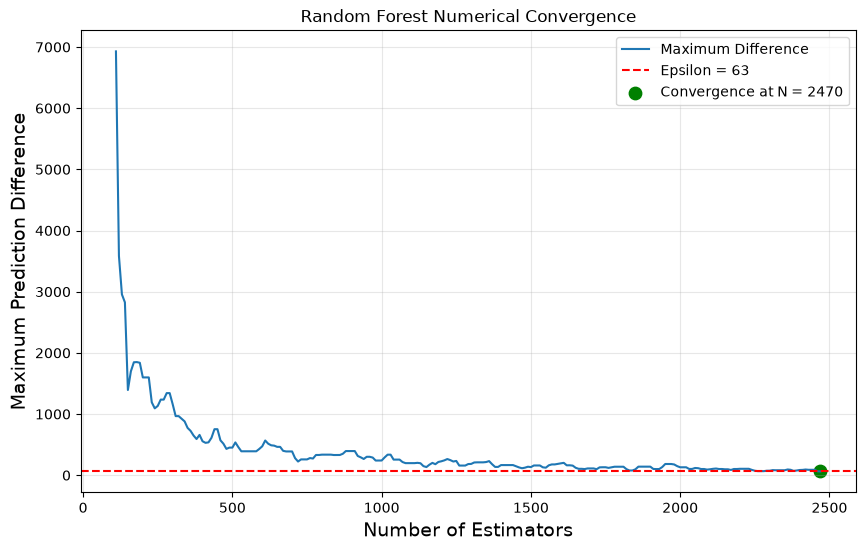

MSE: 175543425.0503585
R^2 Trained: 0.7017208900656178


R^2 Tested: 0.7379785559008647


In [24]:
#To choose n_estimators (the number of trees), we use a Cauchy-style convergence test bounded by a large number.
#We choose a small tolerance epsilon (63 visits) and a large bound N (5,000 trees), and grow the forest step by step.
#Once the predictions over the last window of trees all stay within epsilon of each other, the forest has converged,
#and we keep the smallest number of trees where this happens. If it never happens by N, we stop.

import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from sklearn.base import clone

# Define convergence parameters
epsilon = 63
N_max = 5000
step = 10
window = 100

# Store predictions across the convergence window
predictionWindow = deque(maxlen=window // step + 1)

# Store results for visualization
nValues = []
errorValues = []

# Initialize a separate Random Forest
rfConvergence = clone(rfModel)
rfConvergence.set_params(warm_start=True)

# Initialize convergence variables
converged = False
optimalN = None

# Incrementally construct the Random Forest
for n in range(step, N_max + 1, step):

    rfConvergence.set_params(n_estimators=n)
    rfConvergence.fit(X_train, y_train)

    # Calculate predictions
    predictions = rfConvergence.predict(X_train)
    predictionWindow.append(predictions)

    # Check whether the convergence window is full
    if len(predictionWindow) == predictionWindow.maxlen:

        # Calculate maximum pairwise prediction difference
        predictionArray = np.stack(predictionWindow)
        error = np.max(np.ptp(predictionArray, axis=0))

        # Store results
        nValues.append(n)
        errorValues.append(error)

        # Check convergence criterion
        if error < epsilon:
            optimalN = n
            converged = True
            break

# Report convergence results
if converged:
    print("Convergence achieved!")
    print("Optimal number of estimators:", optimalN)
    print("Final maximum difference:", errorValues[-1])
else:
    print("Convergence not achieved within computational bounds.")
    print("Maximum number of estimators:", N_max)
    print("Final maximum difference:", errorValues[-1])

# Visualize convergence
plt.figure(figsize=(10, 6))
plt.plot(nValues, errorValues, label="Maximum Difference")

plt.axhline(
    y=epsilon,
    color="r",
    linestyle="--",
    label=f"Epsilon = {epsilon}"
)

if converged:
    plt.scatter(
        optimalN,
        errorValues[-1],
        color="green",
        s=80,
        label=f"Convergence at N = {optimalN}"
    )

plt.xlabel("Number of Estimators", fontsize=14)
plt.ylabel("Maximum Prediction Difference", fontsize=14)
plt.title("Random Forest Numerical Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Evaluate the resulting Random Forest
y_predConvergence = rfConvergence.predict(X_test)

print("MSE:", metrics.mean_squared_error(
    y_test, y_predConvergence
))
print("R^2 Trained:", rfConvergence.score(X_train, y_train))
print("R^2 Tested:", rfConvergence.score(X_test, y_test))

The maximum change in predictions drops quickly over the first few hundred trees and then levels off, falling below the 63-visit tolerance at 2,470 trees. Adding trees makes the forest's predictions more stable, but not more accurate here: the test R² of the converged forest (0.738) is essentially the same as the default forest's (0.739). The number of trees mainly controls how consistent the forest is from run to run, while its accuracy depends on how deep and how flexible each tree is, which is what the next step tunes.

This next cell will optimize the depth of the trees. This is more difficult and requires more heavy lifting. Changing the depth of the trees is a trade-off of three other things that come with it: computational complexity, overfitting, and underfitting. As a result of this, optimizing the depth is also optimizing all three of these things. We wish to minimize all of this, which makes this easier. Since increasing d increases the leaves exponentially, we will choose a small d (10 in this case). Then, we calculate and normalize the underfitting, overfitting, and compuational error. We then square all of these and add them. We then use brute force to find the smallest one and that will be our depth (d = 10, so there are only 10 options).

Depth 1 completed.


Depth 2 completed.


Depth 3 completed.


Depth 4 completed.


Depth 5 completed.


Depth 6 completed.


Depth 7 completed.


Depth 8 completed.


Depth 9 completed.


Depth 10 completed.

Optimal Maximum Depth: 3
Minimum Objective Value: 0.0358655348383559

Optimization Results:
 Depth        Error  Overfitting     Cost  Normalized_Error  Normalized_Overfitting  Normalized_Cost  Objective
     1 3.389549e+08     0.023795   7410.0          1.000000                0.000000         0.000000   1.000000
     2 2.420195e+08     0.036106  17290.0          0.165775                0.111675         0.031425   0.040940
     3 2.247243e+08     0.041805  37049.6          0.016933                0.163374         0.094274   0.035866
     4 2.232522e+08     0.058711  75564.4          0.004264                0.316733         0.216778   0.147331
     5 2.227567e+08     0.078590 136465.6          0.000000                0.497058         0.410486   0.415566
     6 2.278113e+08     0.097725 203013.6          0.043500                0.670643         0.622155   0.838731
     7 2.351369e+08     0.113857 255018.8          0.106544                0.816977         0.787568   

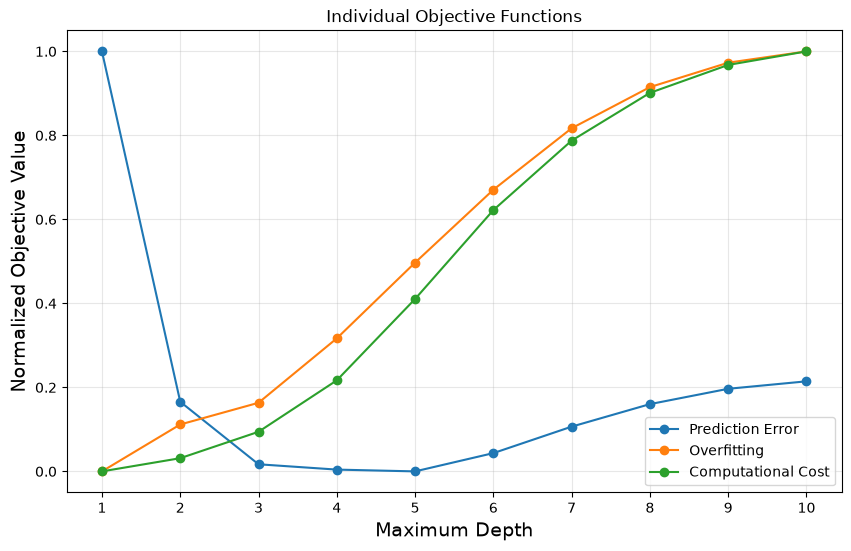

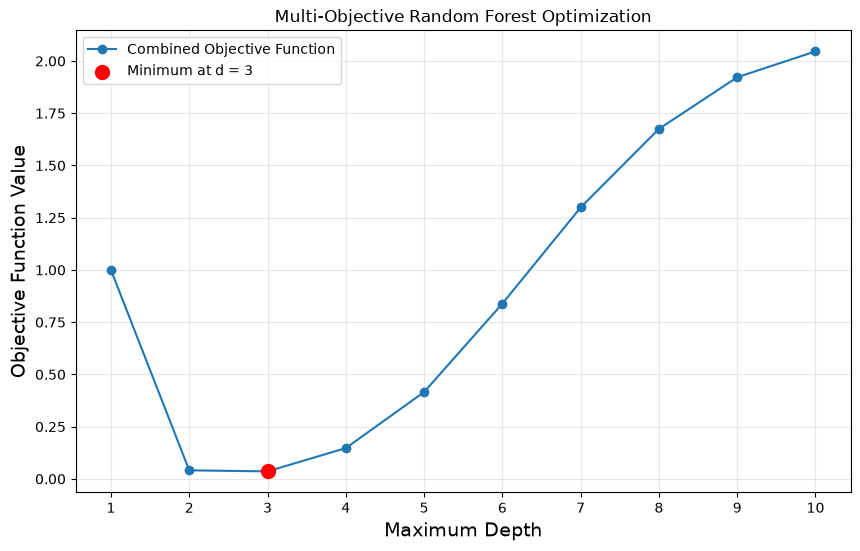


Optimized Random Forest Results:
MSE: 154895564.6186487
RMSE: 12445.704665411626
MAE: 8940.423109334275
R^2: 0.7405429472530155


R^2 Trained: 0.7295889052697612
R^2 Tested: 0.7687981790586217


In [25]:
from sklearn.model_selection import KFold, cross_validate

# Define optimization parameters
depthValues = range(1, 11)
optimalEstimators = 2470

cv = KFold(n_splits=5, shuffle=True, random_state=42)

depthResults = []

# Evaluate each possible maximum depth
for d in depthValues:

    model = clone(rfModel)
    model.set_params(
        n_estimators=optimalEstimators,
        max_depth=d,
        n_jobs=-1,
        warm_start=False
    )

    # Perform cross-validation
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MSE": "neg_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        return_estimator=True,
        error_score="raise"
    )

    # Objective 1: Prediction error
    E = -np.mean(scores["test_MSE"])

    # Objective 2: Overfitting
    O = np.mean(np.maximum(
        0,
        scores["train_R2"] - scores["test_R2"]
    ))

    # Objective 3: Computational cost
    C = np.mean([
        sum(tree.tree_.node_count for tree in forest.estimators_)
        for forest in scores["estimator"]
    ])

    # Store the results
    depthResults.append({
        "Depth": d,
        "Error": E,
        "Overfitting": O,
        "Cost": C
    })

    print(f"Depth {d} completed.")

# Convert results into a DataFrame
depthResults = pd.DataFrame(depthResults)

# Min-max normalization
def normalize(values):
    minimum = values.min()
    maximum = values.max()

    if maximum == minimum:
        return values * 0

    return (values - minimum) / (maximum - minimum)

# Normalize the three objective functions
depthResults["Normalized_Error"] = normalize(
    depthResults["Error"]
)

depthResults["Normalized_Overfitting"] = normalize(
    depthResults["Overfitting"]
)

depthResults["Normalized_Cost"] = normalize(
    depthResults["Cost"]
)

# Calculate the scalar objective function
depthResults["Objective"] = (
    depthResults["Normalized_Error"] ** 2
    + depthResults["Normalized_Overfitting"] ** 2
    + depthResults["Normalized_Cost"] ** 2
)

# Find the global minimum over the evaluated depths
bestDepthRow = depthResults.loc[
    depthResults["Objective"].idxmin()
]

optimalDepth = int(bestDepthRow["Depth"])

# Display results
print("\nOptimal Maximum Depth:", optimalDepth)
print("Minimum Objective Value:", bestDepthRow["Objective"])
print("\nOptimization Results:")
print(depthResults.to_string(index=False))

# Graph the individual normalized objective functions
plt.figure(figsize=(10, 6))

plt.plot(
    depthResults["Depth"],
    depthResults["Normalized_Error"],
    marker="o",
    label="Prediction Error"
)

plt.plot(
    depthResults["Depth"],
    depthResults["Normalized_Overfitting"],
    marker="o",
    label="Overfitting"
)

plt.plot(
    depthResults["Depth"],
    depthResults["Normalized_Cost"],
    marker="o",
    label="Computational Cost"
)

plt.xlabel("Maximum Depth", fontsize=14)
plt.ylabel("Normalized Objective Value", fontsize=14)
plt.title("Individual Objective Functions")
plt.xticks(list(depthValues))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Graph the combined objective function
plt.figure(figsize=(10, 6))

plt.plot(
    depthResults["Depth"],
    depthResults["Objective"],
    marker="o",
    label="Combined Objective Function"
)

plt.scatter(
    optimalDepth,
    bestDepthRow["Objective"],
    color="red",
    s=100,
    zorder=5,
    label=f"Minimum at d = {optimalDepth}"
)

plt.xlabel("Maximum Depth", fontsize=14)
plt.ylabel("Objective Function Value", fontsize=14)
plt.title("Multi-Objective Random Forest Optimization")
plt.xticks(list(depthValues))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Construct the optimized Random Forest
rfModelOptimal = clone(rfModel)

rfModelOptimal.set_params(
    n_estimators=optimalEstimators,
    max_depth=optimalDepth,
    n_jobs=-1,
    warm_start=False
)

rfModelOptimal.fit(X_train, y_train)

# Evaluate the optimized Random Forest
y_predOptimal = rfModelOptimal.predict(X_test)

print("\nOptimized Random Forest Results:")
print("MSE:", metrics.mean_squared_error(y_test, y_predOptimal))
print("RMSE:", np.sqrt(metrics.mean_squared_error(y_test, y_predOptimal)))
print("MAE:", metrics.mean_absolute_error(y_test, y_predOptimal))
print("R^2:", rfModelOptimal.score(X, y))
print("R^2 Trained:", rfModelOptimal.score(X_train, y_train))
print("R^2 Tested:", rfModelOptimal.score(X_test, y_test))

The search balances three measures that depend on depth, each scaled from 0 to 1: prediction error, overfitting (the gap between training and test R²), and computational cost (the total number of nodes in the forest). The prediction error falls sharply from depth 1 to depth 3 and reaches its minimum at depth 5 (about 222.8 million), but overfitting and cost rise steadily with depth. Depth 3 has the lowest combined score (0.036): its error, about 224.7 million, is less than 1% above the best, while its overfitting and cost are much lower than at depth 5. Depth 3 is the better trade-off.

#### 3.1.2 The tuned regression forest

We refit the forest with the chosen settings (2,470 trees, maximum depth 3) on the same 70/30 split and compare its test predictions with the actual values. If the predictions were perfect, every point would fall on the red dashed line.

MSE:  154895564.61864868
R^2: 0.7405429472530155


R^2 Trained: 0.7295889052697612
R^2 Tested: 0.7687981790586217


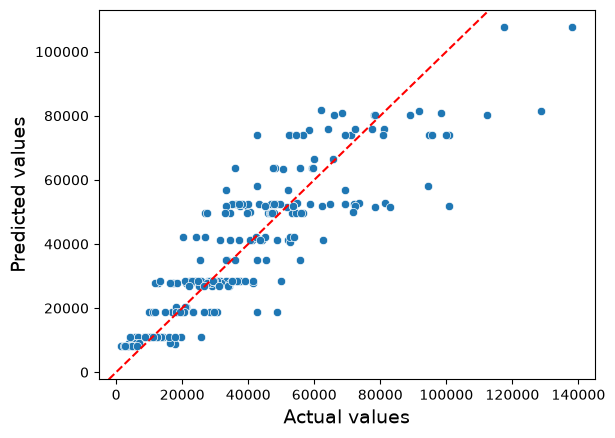

In [26]:
#Optimal forest

#Same tasks as above, just with more information and variables considered

#Regression, 1. Trying to beat the optimized regression tree with EDStations and Total ED Visits

X = data[["EDStations"]]
y = data["Tot_ED_NmbVsts"]

# Create a training/testing split
# 30% of instances held out for testing
# 70% of instances used for training
#We use random_state = 42 for the sake of reproducability
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state= 42)

# Define a regression random forest model
rfModel = RandomForestRegressor(max_depth=3, max_features="sqrt", random_state=99, n_estimators= 2470)

# Fit the model
rfModel.fit(X_train, y_train);

# Predict body mass on the testing data
y_pred = rfModel.predict(X_test)

# Compare testing predictions to actual values
p = sns.scatterplot(x=y_test, y=y_pred)
p.set_xlabel("Actual values", fontsize=14)
p.set_ylabel("Predicted values", fontsize=14)

# Add a diagonal line
# If the testing predictions are close to the actual values,
# points should fall along this line
plt.axline((3000, 3000), (6000, 6000), color="r", ls="--")

# Print mean squared error (MSE)
print("MSE: ", metrics.mean_squared_error(y_test, y_pred))

#R^2 calculation
r_squared = rfModel.score(X, y)
print("R^2:", r_squared)
r_squaredTrain = rfModel.score(X_train, y_train)
print("R^2 Trained:", r_squaredTrain)
r_squaredTest = rfModel.score(X_test, y_test)
print("R^2 Tested:", r_squaredTest)

The tuned forest (2,470 trees, depth 3) reaches an R² of 0.769 on the test set and 0.730 on the training set, with an MSE of about 154.9 million. Its RMSE is 12,446 visits and its MAE is 8,940. The higher test score again shows no sign of overfitting. The predictions now follow the 45-degree line more closely than the first forest's, though, like every model we have built, the forest still underpredicts the busiest EDs, which fall below the red line on the right. Section 3.3 compares this forest with the single tree on equal terms.

### 3.2 Random Forest classification: urban designation

Next we apply a Random Forest to the classification task from Section 2.1, using the same features, held-out hospitals, and grouped folds, so the comparison with the single tree is direct. We tune four settings with grouped cross-validation:

- `max_depth`: how deep each tree may grow.
- `min_samples_leaf`: the fewest training rows in a leaf.
- `max_features`: how many features each split may consider ("sqrt" means about 2 of the 6; None means all 6).
- `class_weight`: none, or balanced.

Each forest has 300 trees, which is plenty for six features.

Best settings: {'class_weight': 'balanced', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 3}
Best cross-validated balanced accuracy: 0.904

Accuracy:            0.903  (no-skill: 0.790)
Balanced accuracy:   0.835
Precision (urban):   0.927
Recall (urban):      0.952
F1-score (urban):    0.940

Classification report:
                precision    recall  f1-score   support

Rural/frontier      0.800     0.718     0.757        39
         Urban      0.927     0.952     0.940       147

      accuracy                          0.903       186
     macro avg      0.864     0.835     0.848       186
  weighted avg      0.900     0.903     0.901       186



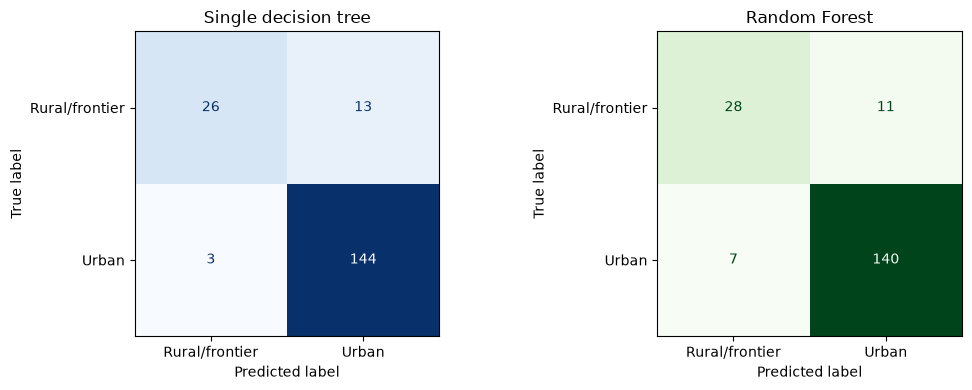

In [27]:
from sklearn.ensemble import RandomForestClassifier

rf_grid = {"max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 3, 5],
           "max_features": ["sqrt", None], "class_weight": [None, "balanced"]}
rfSearch = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), rf_grid,
                        cv=cv_group, scoring="balanced_accuracy")
rfSearch.fit(Xc_train, yc_train)
bestForest = rfSearch.best_estimator_
forest_pred = bestForest.predict(Xc_test)

print("Best settings:", rfSearch.best_params_)
print("Best cross-validated balanced accuracy:", round(rfSearch.best_score_, 3))
print(f"\nAccuracy:            {accuracy_score(yc_test, forest_pred):.3f}  (no-skill: {yc_test.mean():.3f})")
print(f"Balanced accuracy:   {balanced_accuracy_score(yc_test, forest_pred):.3f}")
print(f"Precision (urban):   {precision_score(yc_test, forest_pred):.3f}")
print(f"Recall (urban):      {recall_score(yc_test, forest_pred):.3f}")
print(f"F1-score (urban):    {f1_score(yc_test, forest_pred):.3f}")
print("\nClassification report:")
print(classification_report(yc_test, forest_pred, target_names=["Rural/frontier", "Urban"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(yc_test, tree_pred, display_labels=["Rural/frontier", "Urban"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Single decision tree")
ConfusionMatrixDisplay.from_predictions(yc_test, forest_pred, display_labels=["Rural/frontier", "Urban"],
                                        cmap="Greens", colorbar=False, ax=axes[1])
axes[1].set_title("Random Forest")
plt.tight_layout()
plt.show()

The tuned forest uses 300 trees up to 8 levels deep, at least 3 rows per leaf, about 2 of the 6 features at each split, and balanced class weights. Its cross-validated balanced accuracy of 0.904 is clearly higher than the single tree's 0.850.

On the 74 held-out hospitals, the forest classifies 90.3% of hospital-years correctly, with a balanced accuracy of 0.835. For the urban class, precision is 0.927, recall 0.952, and F1 0.940; for the rural/frontier class, precision is 0.800, recall 0.718, and F1 0.757. The confusion matrices show how the two models differ. The forest finds 28 of the 39 rural or frontier hospital-years, compared with the tree's 26, but it mislabels 7 urban hospitals as rural, compared with the tree's 3. Its total of 18 errors is two more than the tree's 16. On this one test set the two models are close, with the forest slightly better on the smaller class and slightly worse overall.

#### 3.2.1 Generalization and stability

A model generalizes well when its accuracy on new hospitals is close to its accuracy on the hospitals it trained on. We compare the training and test accuracy of each model, and the spread of its balanced accuracy across the five grouped folds. A smaller spread means the model's performance depends less on which hospitals it happens to see.

In [28]:
gen_rows = {}
for name, model, pred in [("Single decision tree", bestTree, tree_pred), ("Random Forest", bestForest, forest_pred)]:
    fold_scores = cross_val_score(model, Xc_train, yc_train, cv=cv_group, scoring="balanced_accuracy")
    gen_rows[name] = {"Training accuracy": accuracy_score(yc_train, model.predict(Xc_train)),
                      "Test accuracy": accuracy_score(yc_test, pred),
                      "Gap (train - test)": accuracy_score(yc_train, model.predict(Xc_train)) - accuracy_score(yc_test, pred),
                      "Test balanced accuracy": balanced_accuracy_score(yc_test, pred),
                      "Test F1 (urban)": f1_score(yc_test, pred),
                      "CV balanced accuracy (mean)": fold_scores.mean(),
                      "CV balanced accuracy (SD)": fold_scores.std()}
display(pd.DataFrame(gen_rows).T.round(3))

,Training accuracy,Test accuracy,Gap (train - test),Test balanced accuracy,Test F1 (urban),CV balanced accuracy (mean),CV balanced accuracy (SD)
Single decision tree,0.963,0.914,0.049,0.823,0.947,0.850,0.075
Random Forest,0.993,0.903,0.090,0.835,0.940,0.904,0.044


The forest fits its training data almost perfectly (99.3% accuracy) because its individual trees are deep, so its gap between training and test accuracy (0.090) is larger than the tree's (0.049). For a forest, that gap is expected and not a warning sign, because the averaging across trees, not the depth of any one tree, is what keeps it from overfitting. The better measures of generalization are the cross-validated results. There, the forest averages a balanced accuracy of 0.904, compared with the tree's 0.850, and its scores vary much less from fold to fold (standard deviation 0.044 versus 0.075). The forest's performance depends less on which hospitals it happens to train on, which is exactly the instability we saw in the unpruned tree. Its small shortfall on the single test set is within the range of variation that the fold-to-fold spread shows.

#### 3.2.2 Feature importance: tree vs. forest

We compare the two models' feature-importance rankings side by side. The forest's importances are averaged over all 300 of its trees.

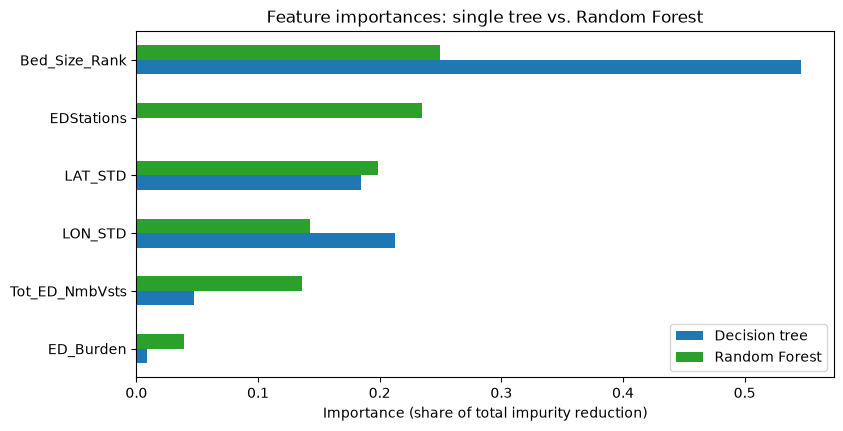

,Decision tree,Random Forest,Decision tree rank,Random Forest rank
Bed_Size_Rank,0.546,0.249,1,1
EDStations,0.000,0.234,6,2
LAT_STD,0.185,0.198,3,3
LON_STD,0.213,0.143,2,4
Tot_ED_NmbVsts,0.048,0.136,4,5
ED_Burden,0.009,0.039,5,6


In [29]:
importance = pd.DataFrame({"Decision tree": bestTree.feature_importances_,
                           "Random Forest": bestForest.feature_importances_}, index=CLASS_FEATURES)
importance = importance.sort_values("Random Forest")

fig, ax = plt.subplots(figsize=(9, 4.5))
importance.plot.barh(ax=ax, color=["tab:blue", "tab:green"])
ax.set(xlabel="Importance (share of total impurity reduction)", title="Feature importances: single tree vs. Random Forest")
plt.show()

ranks = importance.rank(ascending=False).astype(int).add_suffix(" rank")
display(pd.concat([importance.round(3), ranks], axis=1).sort_values("Random Forest rank"))

Bed size rank ranks first in both models, and ED burden ranks last in both, but the forest spreads importance much more evenly. The single tree gave bed size more than half of all the importance (0.546) and gave ED stations none. In the forest, bed size drops to 0.249 and ED stations rise to second place (0.234), with total visits also gaining (0.048 to 0.136). This happens because each split in the forest can consider only about 2 randomly chosen features. When bed size is not among them, the tree has to use another size measure, so stations and visits get their turn. The forest's ranking is a more honest picture of the data: hospital size, measured any of several ways, matters, not bed size alone. Location keeps a similar total share in both models (about 40% in the tree and 34% in the forest), confirming that where a hospital sits is the second key driver of whether it is urban.

#### 3.2.3 The teaching task with a Random Forest

To finish the classification comparison, we apply a Random Forest to the stations-and-burden teaching task from Section 2.2, with balanced class weights and a minimum leaf size of 5, and compare it with the single tree on the same held-out hospitals.

In [30]:
model, features, test_mask = teachModels["Stations + burden, all hospitals"]
train_mask = ~is_test
teachForest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                     random_state=42, n_jobs=-1)
teachForest.fit(data.loc[train_mask, features], y_teach[train_mask])

teach_compare = {}
for name, m in [("Single decision tree", model), ("Random Forest", teachForest)]:
    pred = m.predict(data.loc[test_mask, features])
    y_true = y_teach[test_mask]
    teach_compare[name] = {"Accuracy": accuracy_score(y_true, pred),
                           "Precision": precision_score(y_true, pred, zero_division=0),
                           "Recall": recall_score(y_true, pred), "F1-score": f1_score(y_true, pred)}
display(pd.DataFrame(teach_compare).T.round(3))

,Accuracy,Precision,Recall,F1-score
Single decision tree,0.801,0.179,0.263,0.213
Random Forest,0.801,0.179,0.263,0.213


The forest does no better than the single tree on the teaching task. Both reach 80.1% accuracy with a precision of 0.179, recall of 0.263, and F1-score of 0.213, making the same number of correct and incorrect predictions in each class. Averaging many trees cannot help when the features themselves do not separate the classes, as the scatter plot in Section 2.2 showed. An ensemble reduces the variance of a model, but it cannot supply information the data does not contain.

### 3.3 A fair regression comparison: single tree vs. Random Forest

Section 1 scored the tuned regression tree on the same data it was trained on, while Section 3.1 scored the forest on a held-out 30%. Those numbers are not directly comparable. Here we put both tuned models on equal footing: the same 70/30 split used in Section 3.1, and the same 5-fold cross-validation used in Section 1. Both predict total ED visits from ED stations.

,Train R2,Test R2,Test RMSE,Test MAE,CV R2 (mean),CV R2 (SD),CV RMSE (mean)
Single decision tree (tuned),0.763,0.770,"12,402","8,440",0.740,0.032,"13,688"
Random Forest (tuned),0.730,0.769,"12,446","8,940",0.726,0.036,"14,052"


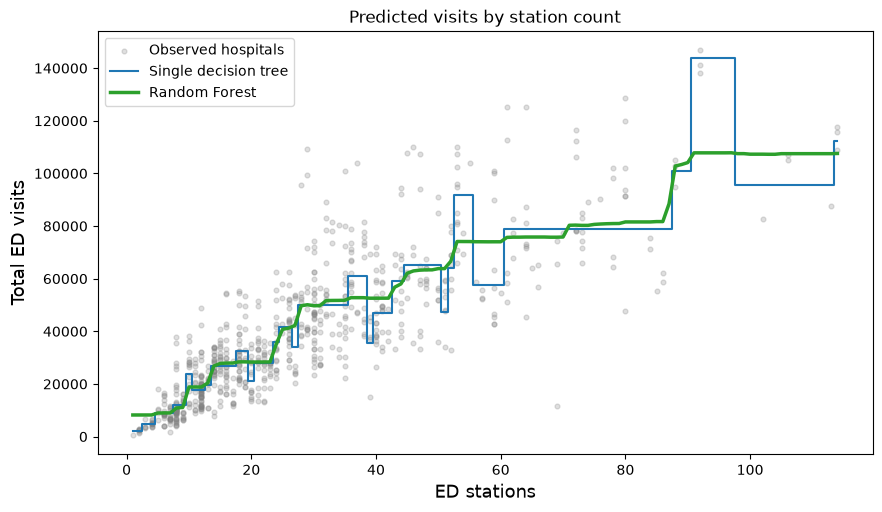

In [31]:
X_reg = data[["EDStations"]]
y_reg = data["Tot_ED_NmbVsts"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)
regCV = KFold(n_splits=5, shuffle=True, random_state=42)

regModels = {
    "Single decision tree (tuned)": DecisionTreeRegressor(max_depth=regtreeModelTotallyOptimal.get_params()["max_depth"],
                                                          max_leaf_nodes=regtreeModelTotallyOptimal.get_params()["max_leaf_nodes"],
                                                          min_samples_leaf=2, random_state=42),
    "Random Forest (tuned)": RandomForestRegressor(n_estimators=2470, max_depth=3, max_features="sqrt",
                                                   random_state=99, n_jobs=-1),
}
reg_rows = {}
for name, model in regModels.items():
    model.fit(Xr_train, yr_train)
    pred = model.predict(Xr_test)
    cv_res = cross_validate(model, X_reg, y_reg, cv=regCV, scoring=("r2", "neg_root_mean_squared_error"))
    reg_rows[name] = {"Train R2": model.score(Xr_train, yr_train),
                      "Test R2": r2_score(yr_test, pred),
                      "Test RMSE": root_mean_squared_error(yr_test, pred),
                      "Test MAE": mean_absolute_error(yr_test, pred),
                      "CV R2 (mean)": cv_res["test_r2"].mean(),
                      "CV R2 (SD)": cv_res["test_r2"].std(),
                      "CV RMSE (mean)": -cv_res["test_neg_root_mean_squared_error"].mean()}
reg_table = pd.DataFrame(reg_rows).T
display(reg_table.style.format({"Train R2": "{:.3f}", "Test R2": "{:.3f}", "Test RMSE": "{:,.0f}", "Test MAE": "{:,.0f}",
                                "CV R2 (mean)": "{:.3f}", "CV R2 (SD)": "{:.3f}", "CV RMSE (mean)": "{:,.0f}"}))

# Predictions across the full range of stations
grid_st = pd.DataFrame({"EDStations": np.arange(1, 115)})
plt.figure(figsize=(10, 5.5))
plt.scatter(X_reg, y_reg, alpha=0.25, s=12, color="gray", label="Observed hospitals")
plt.step(grid_st["EDStations"], regModels["Single decision tree (tuned)"].predict(grid_st), where="mid",
         color="tab:blue", label="Single decision tree")
plt.plot(grid_st["EDStations"], regModels["Random Forest (tuned)"].predict(grid_st), color="tab:green",
         linewidth=2.5, label="Random Forest")
plt.xlabel("ED stations", fontsize=13)
plt.ylabel("Total ED visits", fontsize=13)
plt.title("Predicted visits by station count")
plt.legend()
plt.show()

On equal terms, the single tree and the forest perform almost identically, and the tree is slightly ahead:

| Model | Train R² | Test R² | Test RMSE | Test MAE | CV R² (mean ± SD) | CV RMSE |
|---|---|---|---|---|---|---|
| Single decision tree | 0.763 | 0.770 | 12,402 | 8,440 | 0.740 ± 0.032 | 13,688 |
| Random Forest | 0.730 | 0.769 | 12,446 | 8,940 | 0.726 ± 0.036 | 14,052 |

The reason lies in this task's single input. A Random Forest gets its advantage from building different trees, partly by letting each split consider only some of the features. With only one feature (ED stations), every tree in the forest asks questions about the same variable, so the trees differ only through their bootstrap samples, and the depth limit of 3 keeps each one simple. The plot shows the result. The forest's curve (green) is smoother than the tree's steps (blue) and avoids the tree's dip at 83 to 87 stations and its spike at about 92 stations, but it also levels off at about 108,000 visits and cannot follow the busiest EDs. The tuned tree's extra detail helps slightly more than the forest's smoothing does.

Neither model overfits: in both, the training and test R² are close. The lesson is that a Random Forest is not automatically better. Its strengths show when there are several related features and a flexible base tree, as in the classification task in Section 3.2, not when there is one feature and a shallow tree.

## Conclusion

In this report we built decision trees and Random Forests for both regression and classification on the hospital-level emergency department data.

For regression, a tree predicting total ED visits from station count was tuned with a cross-validated search over depth, number of leaves, and minimum split size. The tuned tree (depth 5, 29 leaves) reached a cross-validated R² of 0.740 and an RMSE of about 13,700 visits, an improvement over the straight line from Report #2 (0.687) and close to our 11-attribute multiple regression. A tree predicting station count from location alone was much weaker (cross-validated R² of 0.418) and showed clear signs of overfitting.

For classification, a tuned tree (depth 6, at least 5 rows per leaf) identified urban hospitals with 91.4% accuracy on 74 hospitals it had never seen, against a no-skill rate of 79.0%, with an F1-score of 0.947 for the urban class and 0.765 for the rural/frontier class. Its splits are easy to read: first bed size, then location. Following our original plan, we also tried predicting teaching status, but every tree was less accurate than simply guessing "non-teaching," because teaching hospitals are scattered among non-teaching ones on every feature we have.

Comparing single trees with Random Forests gave a mixed but instructive result. On urban classification, the forest was clearly more reliable in cross-validation (balanced accuracy 0.904 versus 0.850, with a smaller spread across folds) and better at finding rural and frontier hospitals, though on the single test set it made two more errors than the tree. It also ranked feature importance more evenly, revealing that ED stations and visits matter as much as bed size once the tree is not forced to choose one. On the one-feature regression task, the forest gave no advantage (cross-validated R² of 0.726 versus the tree's 0.740), and on the teaching task, neither model could succeed.

Our main takeaways:

1. Trees are easy to interpret. The urban tree's logic, "is it a small hospital, and is it in a metropolitan region?", can be explained to anyone, which is a real advantage over the SVM from Report #4, which matched its accuracy.
2. A single tree is unstable. The unpruned tree's balanced accuracy ranged from 0.720 to 0.967 across folds, and tuning the leaf size was the most effective way to control that.
3. Random Forests reduce that instability, but only when they have something to work with. They helped most with several related features and did nothing for a one-feature model or for a target the features cannot explain.
4. Evaluation design matters. Scoring a model on its own training data overstated the regression tree's R² (0.776 versus 0.740 in cross-validation) and the location tree's even more (0.630 versus 0.418), and a single test set of 74 hospitals can flatter or understate a model by chance.

For our project goal of directing ED resources where demand is highest, the tuned regression tree gives planners a simple table of expected visits by station count, and hospitals that consistently exceed their band are candidates for added capacity. The urban classification tree shows that a hospital's size and location are enough to place it in the right setting, which supports comparing hospitals with peers in similar settings.